<a href="https://colab.research.google.com/github/supittra/663020034-3_Pandas/blob/main/663020034_3_Pandas_Review.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SC 663 402 Data Warehouse and Big Data Analytics
## แบบฝึกทบทวน pandas

**ผู้สอน:** อ.ดร.พิชญา วิรัชโชติเสถียร (Pitchaya Wiratchotisatian)
**ภาควิชาสถิติ คณะวิทยาศาสตร์ มหาวิทยาลัยขอนแก่น**

---

### วัตถุประสงค์

การบ้านชุดนี้มีวัตถุประสงค์เพื่อทบทวนความรู้ pandas ที่นักศึกษาเคยศึกษามาแล้ว ให้อยู่ในระดับที่พร้อมสำหรับการวิเคราะห์ข้อมูลขนาดใหญ่ในรายวิชานี้
เนื้อหาครอบคลุมตั้งแต่โครงสร้างข้อมูลพื้นฐาน การเลือกและกรองข้อมูล การสรุปข้อมูลด้วย `groupby` การรวมตารางหลายตาราง จนถึงการสร้างกราฟจาก DataFrame

### รูปแบบ

แต่ละหัวข้อประกอบด้วยสองส่วน

1. **ตัวอย่าง** เป็นเซลล์โค้ดที่รันได้ทันที มีไว้เพื่อทบทวนรูปแบบการเรียกใช้คำสั่ง นักศึกษาควรรันและสังเกตผลลัพธ์ก่อนทำโจทย์
2. **โจทย์** เป็นแบบฝึกหัดที่มีระดับความยากสูงกว่าตัวอย่าง ไม่มีเฉลย นักศึกษาต้องเขียนคำตอบเองในเซลล์ที่เตรียมไว้

### ข้อกำหนดในการทำและการส่ง

1. เขียนคำตอบในเซลล์ที่เตรียมไว้ใต้โจทย์แต่ละข้อ
2. โจทย์ที่ระบุคำว่า **อธิบาย** ต้องตอบเป็นข้อความ การส่งเฉพาะโค้ดจะไม่ได้คะแนนในส่วนนั้น
3. ห้ามกำหนดคำตอบเป็นค่าคงที่ ทุกตัวเลขที่รายงานต้องคำนวณจากข้อมูล
4. ให้เขียนโปรแกรมในรูปแบบ vectorized เป็นหลัก หากจำเป็นต้องใช้การวนซ้ำทีละแถว ให้ระบุเหตุผลกำกับ
5. ก่อนส่งให้เลือกคำสั่ง Restart & Run All และตรวจสอบว่าไฟล์ทำงานได้ตลอดทั้งไฟล์
6. ส่งไฟล์ในรูปแบบ `.ipynb` ด้วยลิ้งก์ใน GitHub ของตนเอง

### เกณฑ์การประเมิน

* ความเรียบร้อย ครบถ้วน และความสามารถในการรันซ้ำได้

---
## ส่วนที่ 0 import libraries และ เตรียมข้อมูล

ชุดข้อมูลที่ใช้ประกอบด้วย 3 ตาราง ได้แก่ ข้อมูลสภาพอากาศรายวัน ข้อมูลเมือง และข้อมูลภูมิภาค
ให้รันเซลล์ต่อไปนี้เพื่อโหลดข้อมูลก่อนเริ่มทำการบ้าน

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  fonts-tlwg-garuda fonts-tlwg-garuda-ttf fonts-tlwg-kinnari
  fonts-tlwg-kinnari-ttf fonts-tlwg-laksaman fonts-tlwg-laksaman-ttf
  fonts-tlwg-loma fonts-tlwg-loma-ttf fonts-tlwg-mono fonts-tlwg-mono-ttf
  fonts-tlwg-norasi fonts-tlwg-norasi-ttf fonts-tlwg-purisa
  fonts-tlwg-purisa-ttf fonts-tlwg-sawasdee fonts-tlwg-sawasdee-ttf
  fonts-tlwg-typewriter fonts-tlwg-typewriter-ttf fonts-tlwg-typist
  fonts-tlwg-typist-ttf fonts-tlwg-typo fonts-tlwg-typo-ttf fonts-tlwg-umpush
  fonts-tlwg-umpush-ttf fonts-tlwg-waree fonts-tlwg-waree-ttf
The following NEW packages will be installed:
  fonts-thai-tlwg fonts-tlwg-garuda fonts-tlwg-garuda-ttf fonts-tlwg-kinnari
  fonts-tlwg-kinnari-ttf fonts-tlwg-laksaman fonts-tlwg-laksaman-ttf
  fonts-tlwg-loma fonts-tlwg-loma-ttf fonts-tlwg-mono fonts-tlwg-mono-ttf
  fonts-tlwg-norasi fonts-tlwg-norasi-ttf fo

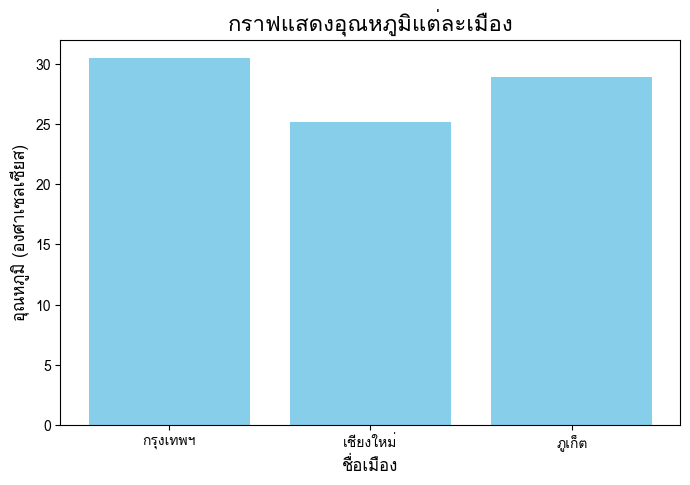

In [ ]:
import pandas as pd
import numpy as np
import os, shutil
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

# 1. ติดตั้งฟอนต์ภาษาไทย
!apt-get -y install fonts-thai-tlwg

# 2. ล้าง cache ของ matplotlib เพื่ออัปเดตฟอนต์ใหม่
cache_dir = matplotlib.get_cachedir()
if os.path.exists(cache_dir):
    shutil.rmtree(cache_dir)

# 3. ลงทะเบียนฟอนต์ใหม่เข้ากับ FontManager
font_path = '/usr/share/fonts/truetype/tlwg/Loma.ttf'
if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)

# 4. ตั้งค่าฟอนต์หลัก
plt.rcParams['font.family'] = 'Loma'
plt.rcParams['axes.unicode_minus'] = False

# 5. สร้างข้อมูลจำลองและแสดงผล
data = {
    'เมือง': ['กรุงเทพฯ', 'เชียงใหม่', 'ภูเก็ต'],
    'อุณหภูมิ': [30.5, 25.2, 28.9]
}
df_thai = pd.DataFrame(data)

print("ตั้งค่าระบบฟอนต์ภาษาไทยสำเร็จ!")

plt.figure(figsize=(8, 5))
plt.bar(df_thai['เมือง'], df_thai['อุณหภูมิ'], color='skyblue')
plt.title('กราฟแสดงอุณหภูมิแต่ละเมือง', fontsize=16)
plt.xlabel('ชื่อเมือง', fontsize=12)
plt.ylabel('อุณหภูมิ (องศาเซลเซียส)', fontsize=12)
plt.show()

In [ ]:
import pandas as pd
import numpy as np

BASE = ("https://raw.githubusercontent.com/PitchayaW/"
        "SC-612-104-Essential-Data-Science/refs/heads/main/Module-A-Notebooks/Dataset/")

df = pd.read_csv(BASE + "world_weather_sample.csv")
city_info = pd.read_csv(BASE + "city_info.csv")
region_info = pd.read_csv(BASE + "region_info.csv")

print("weather:", df.shape, " city_info:", city_info.shape, " region_info:", region_info.shape)
df.head()

weather: (2075, 10)  city_info: (23, 5)  region_info: (6, 3)


,record_id,date,city,country,region,temperature_c,humidity_pct,rainfall_mm,wind_speed_kmh,pressure_hpa
0,983,2025-03-24,New York,USA,North America,15.7,72.6,6.3,15.9,1005.4
1,220,2025-02-09,Tokyo,Japan,Asia,18.3,60.6,0.0,20.5,1015.1
2,1022,2025-02-01,Los Angeles,USA,North America,20.6,46.8,1.2,8.6,1013.5
3,469,2025-01-19,Mumbai,India,Asia,31.0,73.4,8.0,11.8,1000.1
4,1834,2025-02-03,Cape Town,South Africa,Africa,19.1,55.0,0.0,16.6,1015.1


---
## ข้อ 1 การเปรียบเทียบคำสั่งที่มีลักษณะใกล้เคียงกัน

**คำสั่ง:** ให้นักศึกษารันเซลล์โค้ดทั้ง 6 เซลล์ต่อไปนี้ สังเกตผลลัพธ์ที่ได้ แล้วอธิบายกับตนเองให้เข้าใจความแตกต่างของคำสั่งในแต่ละเซลล์ พร้อมระบุว่าในทางปฏิบัติควรเลือกใช้คำสั่งใดในสถานการณ์ใด

การอธิบายควรครอบคลุมทั้ง **ชนิดของผลลัพธ์** **รูปร่างของผลลัพธ์** และ **ความหมายของค่าที่ได้**

In [ ]:
# เซลล์ 1.1
s = pd.Series([10, 20, 30], index=["a", "b", "c"])
print(s["a"])
print(s.iloc[0])
print(s[["a", "c"]])

10
10
a    10
c    30
dtype: int64


In [ ]:
# เซลล์ 1.2
print(type(df["city"]), df["city"].shape)
print(type(df[["city"]]), df[["city"]].shape)

<class 'pandas.core.series.Series'> (2075,)
<class 'pandas.core.frame.DataFrame'> (2075, 1)


In [ ]:
# เซลล์ 1.3
print(df.loc[0:3].shape)
print(df.iloc[0:3].shape)

(4, 10)
(3, 10)


In [ ]:
# เซลล์ 1.4
print(df.groupby("city")["temperature_c"].count().head(3))
print(df.groupby("city").size().head(3))

city
Auckland    90
Bangkok     91
Beijing     89
Name: temperature_c, dtype: int64
city
Auckland    90
Bangkok     91
Beijing     90
dtype: int64


In [ ]:
# เซลล์ 1.5
print(df.groupby("city")["temperature_c"].mean().head(3))
print(df.groupby("city")[["temperature_c"]].mean().head(3))

city
Auckland    17.804444
Bangkok     32.453846
Beijing     15.598876
Name: temperature_c, dtype: float64
          temperature_c
city                   
Auckland      17.804444
Bangkok       32.453846
Beijing       15.598876


In [ ]:
# เซลล์ 1.6
a = pd.Series([1, 2, 3], index=["x", "y", "z"])
b = pd.Series([10, 20, 30], index=["z", "y", "x"])
print(a + b)
print(a.to_numpy() + b.to_numpy())

x    31
y    22
z    13
dtype: int64
[11 22 33]


---
## ข้อ 2 Series และ DataFrame

### ตัวอย่าง

In [ ]:
# การสร้าง DataFrame จากโครงสร้างข้อมูลสองรูปแบบ
d1 = pd.DataFrame({"city": ["Bangkok", "Tokyo"], "temp": [30.5, 16.2]})
d2 = pd.DataFrame([{"city": "Bangkok", "temp": 30.5}, {"city": "Tokyo", "temp": 16.2}])
print(d1.equals(d2))

# การเข้าถึงองค์ประกอบของ DataFrame
print(df.columns.tolist())
print(df.index[:5].tolist())
print(df["temperature_c"].nlargest(3).tolist())

True
['record_id', 'date', 'city', 'country', 'region', 'temperature_c', 'humidity_pct', 'rainfall_mm', 'wind_speed_kmh', 'pressure_hpa']
[0, 1, 2, 3, 4]
[999.0, 999.0, 999.0]


### โจทย์ 2.1
สร้าง Series ชื่อ `rain_by_city` ซึ่งเก็บปริมาณฝนรวมของแต่ละเมือง โดยกำหนดให้ index เป็นชื่อเมือง จากนั้นตอบคำถามต่อไปนี้ด้วยโปรแกรม

1. เมืองที่มีปริมาณฝนรวมสูงสุด 3 อันดับแรก
2. สัดส่วนปริมาณฝนของแต่ละเมืองเทียบกับปริมาณฝนรวมทั้งหมด แสดงเป็นร้อยละทศนิยม 2 ตำแหน่ง
3. จำนวนเมืองที่มีปริมาณฝนรวมสูงกว่าค่าเฉลี่ยของทุกเมือง

In [ ]:
# คำตอบข้อ 2.1.1
rain_by_city = df.groupby("city")["rainfall_mm"].sum()
rain_by_city.nlargest(3)

,rainfall_mm
city,
Singapore,870.4
Bangkok,685.6
Lagos,652.8


In [ ]:
# คำตอบข้อ 2.1.2
rain_share_pct = (rain_by_city / rain_by_city.sum() * 100).round(2)
rain_share_pct.sort_values(ascending=False)

,rainfall_mm
city,
Singapore,10.43
Bangkok,8.21
Lagos,7.82
Mumbai,5.84
Chiang Mai,5.22
Sao Paulo,5.07
Nairobi,4.74
Tokyo,4.61
Auckland,4.22


In [ ]:
# คำตอบข้อ 2.1.3
n_above_mean = (rain_by_city > rain_by_city.mean()).sum()
print("ค่าเฉลี่ยฝนรวมต่อเมือง:", round(rain_by_city.mean(), 2), "มม.")
print("จำนวนเมืองที่สูงกว่าค่าเฉลี่ย:", n_above_mean, "จาก", len(rain_by_city), "เมือง")

ค่าเฉลี่ยฝนรวมต่อเมือง: 362.97 มม.
จำนวนเมืองที่สูงกว่าค่าเฉลี่ย: 8 จาก 23 เมือง


### โจทย์ 2.2
สร้าง DataFrame ชื่อ `city_profile` ที่มีหนึ่งแถวต่อหนึ่งเมือง ประกอบด้วยคอลัมน์
`city`, `country`, `region`, `n_records`, `avg_temp`, `total_rain`
โดยกำหนดให้ใช้ `groupby`

In [ ]:
# คำตอบข้อ 2.2
city_profile = (
    df.groupby("city", as_index=False)
      .agg(
          country=("country", lambda s: s.mode().iat[0]),
          region=("region", lambda s: s.mode().iat[0]),
          n_records=("record_id", "size"),
          avg_temp=("temperature_c", "mean"),
          total_rain=("rainfall_mm", "sum"),
      )
      .round({"avg_temp": 2, "total_rain": 1})
)
print(city_profile.shape)
city_profile

(23, 6)


,city,country,region,n_records,avg_temp,total_rain
0,Auckland,New Zealand,Oceania,90,17.80,351.9
1,Bangkok,Thailand,Asia,91,32.45,685.6
2,Beijing,China,Asia,90,15.60,250.1
3,Berlin,Germany,Europe,90,12.38,268.4
4,Buenos Aires,Argentina,South America,90,19.17,305.1
5,Cairo,Egypt,Africa,91,26.09,123.0
6,Cape Town,South Africa,Africa,90,30.16,239.3
7,Chiang Mai,Thailand,Asia,91,29.68,435.6
8,Lagos,Nigeria,Africa,90,29.49,652.8
9,Lima,Peru,South America,90,21.49,180.3


---
## ข้อ 3 การนำเข้าข้อมูลด้วย `read_csv()`

### ตัวอย่าง

In [ ]:
# พารามิเตอร์ที่ใช้บ่อย ได้แก่ usecols, nrows, parse_dates, dtype, na_values
preview = pd.read_csv(
    BASE + "world_weather_sample.csv",
    usecols=["city", "date", "temperature_c"],
    parse_dates=["date"],
    nrows=5,
)
print(preview.dtypes)
preview

date             datetime64[ns]
city                     object
temperature_c           float64
dtype: object


,date,city,temperature_c
0,2025-03-24,New York,15.7
1,2025-02-09,Tokyo,18.3
2,2025-02-01,Los Angeles,20.6
3,2025-01-19,Mumbai,31.0
4,2025-02-03,Cape Town,19.1


In [ ]:
# การอ่านข้อมูลทีละก้อนด้วย chunksize ซึ่งคืนค่าเป็น iterator
total_rows = 0
for chunk in pd.read_csv(BASE + "world_weather_sample.csv", chunksize=500):
    total_rows += len(chunk)
print("จำนวนแถวรวม:", total_rows)

จำนวนแถวรวม: 2075


### โจทย์ 3.1
เขียนคำสั่ง `pd.read_csv()` เพียงคำสั่งเดียวที่ดำเนินการทุกข้อต่อไปนี้ให้เสร็จสิ้นตั้งแต่ขั้นตอนการนำเข้า

1. อ่านเฉพาะคอลัมน์ `date`, `city`, `region`, `temperature_c`, `humidity_pct`, `rainfall_mm`
2. แปลงคอลัมน์ `date` เป็นชนิด datetime
3. กำหนดให้ค่า `999` และ `-999` ถูกอ่านเป็นค่าว่าง
4. กำหนดชนิดข้อมูลของ `city` และ `region` เป็น `category`
5. กำหนดให้ `city` เป็น index

ให้ตรวจสอบผลด้วย `.dtypes` และ `.info()`

In [ ]:
# คำตอบข้อ 3.1
df_opt = pd.read_csv(
    BASE + "world_weather_sample.csv",
    usecols=["date", "city", "region", "temperature_c", "humidity_pct", "rainfall_mm"],  # (1)
    parse_dates=["date"],                                                                # (2)
    na_values=[999, -999],                                                               # (3)
    dtype={"city": "category", "region": "category"},                                    # (4)
    index_col="city",                                                                    # (5)
)
df_opt.head()

,date,region,temperature_c,humidity_pct,rainfall_mm
city,,,,,
New York,2025-03-24,North America,15.7,72.6,6.3
Tokyo,2025-02-09,Asia,18.3,60.6,0.0
Los Angeles,2025-02-01,North America,20.6,46.8,1.2
Mumbai,2025-01-19,Asia,31.0,73.4,8.0
Cape Town,2025-02-03,Africa,19.1,55.0,0.0


In [ ]:
print(df_opt.dtypes)
print("index:", df_opt.index.name, "| dtype:", df_opt.index.dtype.name)
print("ค่าสูงสุดของอุณหภูมิหลังอ่าน 999 เป็นค่าว่าง:", df_opt["temperature_c"].max())
print()
df_opt.info()

date             datetime64[ns]
region                 category
temperature_c           float64
humidity_pct            float64
rainfall_mm             float64
dtype: object
index: city | dtype: category
ค่าสูงสุดของอุณหภูมิหลังอ่าน 999 เป็นค่าว่าง: 39.2

<class 'pandas.core.frame.DataFrame'>
CategoricalIndex: 2075 entries, New York to Paris
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           2075 non-null   datetime64[ns]
 1   region         2075 non-null   category      
 2   temperature_c  2052 non-null   float64       
 3   humidity_pct   1993 non-null   float64       
 4   rainfall_mm    2013 non-null   float64       
dtypes: category(1), datetime64[ns](1), float64(3)
memory usage: 69.8 KB


### โจทย์ 3.2
เปรียบเทียบปริมาณหน่วยความจำที่ใช้ระหว่างตารางที่นำเข้าตามปกติกับตารางจากโจทย์ 3.1 ด้วย `.memory_usage(deep=True)`
รายงานผลเป็นร้อยละที่ลดลง และ **อธิบาย** ว่าคอลัมน์ใดมีผลต่อการลดลงมากที่สุด เพราะเหตุใด

In [ ]:
# คำตอบข้อ 3.2
df_default = pd.read_csv(BASE + "world_weather_sample.csv")

mem_default = df_default.memory_usage(deep=True)
mem_opt = df_opt.memory_usage(deep=True)

total_default, total_opt = mem_default.sum(), mem_opt.sum()
pct_saved = (1 - total_opt / total_default) * 100

print(f"นำเข้าตามปกติ : {total_default / 1024:,.1f} KB")
print(f"ตารางข้อ 3.1  : {total_opt / 1024:,.1f} KB")
print(f"ลดลง          : {pct_saved:.1f} %")

mem_compare = (
    pd.DataFrame({
        "default_bytes": mem_default,
        "optimized_bytes": mem_opt.rename({"Index": "city"}),
    })
    .fillna(0)
    .astype(int)
    .assign(
        saved_bytes=lambda d: d["default_bytes"] - d["optimized_bytes"],
        pct_of_saving=lambda d: (d["saved_bytes"] / d["saved_bytes"].sum() * 100).round(1),
        note=lambda d: np.where(d["optimized_bytes"] == 0, "ไม่ได้อ่านเข้ามา", "ยังอยู่ในตาราง"),
    )
    .sort_values("saved_bytes", ascending=False)
)

still_there = mem_compare[mem_compare["note"] == "ยังอยู่ในตาราง"]
print("คอลัมน์ที่ยังอยู่ในตารางและลดลงมากที่สุด:", still_there["saved_bytes"].idxmax())
mem_compare

นำเข้าตามปกติ : 558.2 KB
ตารางข้อ 3.1  : 71.2 KB
ลดลง          : 87.2 %
คอลัมน์ที่ยังอยู่ในตารางและลดลงมากที่สุด: region


,default_bytes,optimized_bytes,saved_bytes,pct_of_saving,note
region,117631,2590,115041,23.1,ยังอยู่ในตาราง
country,114937,0,114937,23.0,ไม่ได้อ่านเข้ามา
city,116920,3927,112993,22.7,ยังอยู่ในตาราง
date,122425,16600,105825,21.2,ยังอยู่ในตาราง
wind_speed_kmh,16600,0,16600,3.3,ไม่ได้อ่านเข้ามา
record_id,16600,0,16600,3.3,ไม่ได้อ่านเข้ามา
pressure_hpa,16600,0,16600,3.3,ไม่ได้อ่านเข้ามา
Index,132,0,132,0.0,ไม่ได้อ่านเข้ามา
humidity_pct,16600,16600,0,0.0,ยังอยู่ในตาราง
rainfall_mm,16600,16600,0,0.0,ยังอยู่ในตาราง


### โจทย์ 3.3
ใช้การอ่านข้อมูลแบบ `chunksize` เพื่อคำนวณค่าต่อไปนี้ โดยห้ามโหลดข้อมูลทั้งไฟล์เข้าหน่วยความจำพร้อมกัน และห้ามใช้ `pd.concat`

1. อุณหภูมิสูงสุดและต่ำสุดของทั้งไฟล์
2. อุณหภูมิเฉลี่ยรายเมือง

**อธิบาย:** เหตุใดการนำค่าเฉลี่ยของแต่ละก้อนมาเฉลี่ยกันอีกครั้งจึงให้ผลไม่ถูกต้อง และควรสะสมค่าใดแทนจึงจะได้ผลที่ถูกต้อง

In [ ]:
# คำตอบข้อ 3.3
temp_max, temp_min = -np.inf, np.inf
sum_by_city = pd.Series(dtype="float64")
count_by_city = pd.Series(dtype="float64")

reader = pd.read_csv(
    BASE + "world_weather_sample.csv",
    usecols=["city", "temperature_c"],
    na_values=[999, -999],
    chunksize=500,
)
for chunk in reader:
    temp_max = np.fmax(temp_max, chunk["temperature_c"].max())
    temp_min = np.fmin(temp_min, chunk["temperature_c"].min())
    part = chunk.groupby("city")["temperature_c"].agg(["sum", "count"])
    sum_by_city = sum_by_city.add(part["sum"], fill_value=0)
    count_by_city = count_by_city.add(part["count"], fill_value=0)

print("จำนวนค่าอุณหภูมิที่ไม่ว่าง:", int(count_by_city.sum()))

print("อุณหภูมิสูงสุด:", temp_max)
print("อุณหภูมิต่ำสุด:", temp_min)

avg_temp_by_city = (sum_by_city / count_by_city).rename("avg_temp").rename_axis("city")
avg_temp_by_city

จำนวนค่าอุณหภูมิที่ไม่ว่าง: 2052
อุณหภูมิสูงสุด: 39.2
อุณหภูมิต่ำสุด: -88.0


,avg_temp
city,
Auckland,17.804444
Bangkok,32.453846
Beijing,15.598876
Berlin,12.383146
Buenos Aires,19.171910
Cairo,26.089888
Cape Town,19.153409
Chiang Mai,29.680220
Lagos,29.494253


---
## ข้อ 4 การสำรวจข้อมูลและการตรวจสอบคุณภาพข้อมูล

### ตัวอย่าง

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075 entries, 0 to 2074
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   record_id       2075 non-null   int64  
 1   date            2075 non-null   object 
 2   city            2075 non-null   object 
 3   country         2075 non-null   object 
 4   region          2075 non-null   object 
 5   temperature_c   2055 non-null   float64
 6   humidity_pct    1993 non-null   float64
 7   rainfall_mm     2013 non-null   float64
 8   wind_speed_kmh  2034 non-null   float64
 9   pressure_hpa    2043 non-null   float64
dtypes: float64(5), int64(1), object(4)
memory usage: 162.2+ KB


In [ ]:
print(df.describe().round(2))
print(df.describe(include="all").iloc[:4])

       record_id  temperature_c  humidity_pct  rainfall_mm  wind_speed_kmh  \
count    2075.00        2055.00       1993.00      2013.00         2034.00   
mean     1035.15          21.84         66.82         4.15           14.78   
std       598.02          38.22         13.09         3.85            5.88   
min         1.00         -88.00         21.50         0.00           -5.00   
25%       517.50          15.40         58.60         0.30           10.80   
50%      1035.00          20.00         67.10         3.50           15.00   
75%      1553.50          25.70         75.50         6.60           18.70   
max      2070.00         999.00        150.00        17.60           33.70   

       pressure_hpa  
count       2043.00  
mean        1013.13  
std            5.86  
min          993.90  
25%         1009.30  
50%         1013.10  
75%         1017.20  
max         1030.60  
        record_id        date        city   country region  temperature_c  \
count      2075.0     

In [ ]:
print(df.isna().sum())
print("จำนวนแถวที่มีค่าว่างอย่างน้อยหนึ่งคอลัมน์:", df.isna().any(axis=1).sum())
print("จำนวนแถวที่ซ้ำกันทุกคอลัมน์:", df.duplicated().sum())

record_id          0
date               0
city               0
country            0
region             0
temperature_c     20
humidity_pct      82
rainfall_mm       62
wind_speed_kmh    41
pressure_hpa      32
dtype: int64
จำนวนแถวที่มีค่าว่างอย่างน้อยหนึ่งคอลัมน์: 229
จำนวนแถวที่ซ้ำกันทุกคอลัมน์: 5


### โจทย์ 4.1
สร้าง DataFrame ชื่อ `summary` ที่มีหนึ่งแถวต่อหนึ่งคอลัมน์ของ `df` ประกอบด้วย
`dtype`, `n_missing`, `pct_missing`, `n_unique`, `example_value`
โดยห้ามใช้การวนซ้ำทีละคอลัมน์ และให้เรียงลำดับจากคอลัมน์ที่มีค่าว่างมากที่สุด

In [ ]:
# คำตอบข้อ 4.1
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(2),
    "n_unique": df.nunique(),
    "example_value": df.bfill().iloc[0],      # ค่าแรกที่ไม่ว่างของแต่ละคอลัมน์
}).sort_values("n_missing", ascending=False)
summary

,dtype,n_missing,pct_missing,n_unique,example_value
humidity_pct,float64,82,3.95,544,72.6
rainfall_mm,float64,62,2.99,164,6.3
wind_speed_kmh,float64,41,1.98,278,15.9
pressure_hpa,float64,32,1.54,294,1005.4
temperature_c,float64,20,0.96,331,15.7
record_id,int64,0,0.00,2070,983
date,object,0,0.00,90,2025-03-24
region,object,0,0.00,6,North America
city,object,0,0.00,23,New York
country,object,0,0.00,28,USA


### โจทย์ 4.2
ผลลัพธ์ของ `.describe()` แสดงค่าสูงสุดของ `temperature_c` และ `humidity_pct` ที่เป็นไปไม่ได้ในทางกายภาพ ให้เขียนโปรแกรมหาค่าต่อไปนี้

1. จำนวนแถวที่ `temperature_c` อยู่นอกช่วง -60 ถึง 60
2. จำนวนแถวที่ `humidity_pct` อยู่นอกช่วง 0 ถึง 100
3. จำนวนแถวที่มีความผิดปกติอย่างน้อยหนึ่งคอลัมน์ โดยระวังการนับซ้ำ

In [ ]:
# คำตอบข้อ 4.2
bad_temp = df["temperature_c"].notna() & ~df["temperature_c"].between(-60, 60)
print("แถวที่อุณหภูมิอยู่นอกช่วง:", bad_temp.sum())
print("ค่าที่พบ:", sorted(df.loc[bad_temp, "temperature_c"].unique().tolist()))

bad_humidity = df["humidity_pct"].notna() & ~df["humidity_pct"].between(0, 100)
print("แถวที่ความชื้นอยู่นอกช่วง:", bad_humidity.sum())
print("ค่าที่พบ:", sorted(df.loc[bad_humidity, "humidity_pct"].unique().tolist()))

bad_any = bad_temp | bad_humidity
print("ผิดปกติอย่างน้อยหนึ่งคอลัมน์:", bad_any.sum())
print("ผิดปกติทั้งสองคอลัมน์พร้อมกัน:", (bad_temp & bad_humidity).sum())
print("ผลบวกของข้อ (1) และ (2):", bad_temp.sum() + bad_humidity.sum())

แถวที่อุณหภูมิอยู่นอกช่วง: 5
ค่าที่พบ: [-88.0, 999.0]
แถวที่ความชื้นอยู่นอกช่วง: 3
ค่าที่พบ: [150.0]
ผิดปกติอย่างน้อยหนึ่งคอลัมน์: 8
ผิดปกติทั้งสองคอลัมน์พร้อมกัน: 0
ผลบวกของข้อ (1) และ (2): 8


### โจทย์ 4.3
คอลัมน์ `country` มีจำนวนค่าไม่ซ้ำมากกว่าจำนวนประเทศที่มีอยู่จริง เนื่องจากการใช้ตัวพิมพ์ไม่สม่ำเสมอ

1. แสดงว่าค่าใดบ้างที่หมายถึงประเทศเดียวกันแต่ถูกนับแยกจากกัน
2. ทดลองใช้ `df["country"].str.title()` แล้ว **อธิบาย** ว่าวิธีนี้ทำให้ข้อมูลของประเทศใดเสียหาย และเพราะเหตุใด
3. เสนอและเขียนวิธี normalize ที่ถูกต้อง โดยต้องรองรับกรณีที่มีช่องว่างหัวท้ายด้วย

> **การตรวจสอบคำตอบ:** จำนวนประเทศที่ถูกต้องคือ 21 ประเทศ จากทั้งหมด 23 เมือง

In [ ]:
# คำตอบข้อ 4.3
country_key = df["country"].str.strip().str.casefold()

variants = (
    df.groupby(country_key)["country"]
      .agg(n_variants="nunique", written_as=lambda s: ", ".join(sorted(map(repr, s.unique()))))
      .query("n_variants > 1")
)
print("จำนวนค่าไม่ซ้ำของ country:", df["country"].nunique())
variants

title_result = (
    df[["country"]].drop_duplicates()
      .assign(before=lambda d: d["country"].map(repr),
              after_title=lambda d: d["country"].str.title().map(repr))
      .sort_values("after_title")[["before", "after_title"]]
      .reset_index(drop=True)
)
print("จำนวนค่าไม่ซ้ำหลัง .str.title():", df["country"].str.title().nunique())
title_result



จำนวนค่าไม่ซ้ำของ country: 28
จำนวนค่าไม่ซ้ำหลัง .str.title(): 21


,before,after_title
0,'ARGENTINA','Argentina'
1,'Argentina','Argentina'
2,'Australia','Australia'
3,'Brazil','Brazil'
4,'CANADA','Canada'
5,'Canada','Canada'
6,'China','China'
7,'Egypt','Egypt'
8,'France','France'
9,'GERMANY','Germany'


In [ ]:
def normalize_country(s):
    stripped = s.str.strip()
    key = stripped.str.casefold()
    canonical = stripped.groupby(key).agg(lambda g: g.value_counts().idxmax())
    return key.map(canonical)

country_clean = normalize_country(df["country"])

# ค่าที่ .str.title() จะทำให้ผิดไปจากชื่อที่ถูกต้อง
broken_by_title = country_clean[country_clean != country_clean.str.title()].unique().tolist()
print("ค่าที่เสียหายหากใช้ .str.title():", broken_by_title)

df["country"] = country_clean
print("จำนวนประเทศหลัง normalize:", df["country"].nunique(), "| จำนวนเมือง:", df["city"].nunique())
print("ทุกเมืองอยู่ในประเทศเดียว:", (df.groupby("city")["country"].nunique() == 1).all())
sorted(df["country"].unique())

ค่าที่เสียหายหากใช้ .str.title(): ['USA', 'UK']
จำนวนประเทศหลัง normalize: 21 | จำนวนเมือง: 23
ทุกเมืองอยู่ในประเทศเดียว: True


['Argentina',
 'Australia',
 'Brazil',
 'Canada',
 'China',
 'Egypt',
 'France',
 'Germany',
 'India',
 'Japan',
 'Kenya',
 'Mexico',
 'New Zealand',
 'Nigeria',
 'Peru',
 'Russia',
 'Singapore',
 'South Africa',
 'Thailand',
 'UK',
 'USA']

---
## ข้อ 5 การเลือกข้อมูลด้วย `loc` และ `iloc`

### ตัวอย่าง

In [ ]:
# iloc อ้างอิงตามตำแหน่ง ส่วน loc อ้างอิงตาม label และรวมค่าปลายช่วง
print(df.iloc[0:3, 0:3].shape, df.loc[0:3, ["city", "region"]].shape)

# loc ใช้ร่วมกับเงื่อนไขและเลือกคอลัมน์ได้ในคำสั่งเดียว
print(df.loc[df["temperature_c"] > 35, ["city", "date", "temperature_c"]].head(3))

(3, 3) (4, 2)
          city        date  temperature_c
78   Cape Town  2025-02-10          999.0
161    Bangkok  2025-02-14           38.6
325     Mumbai  2025-03-31           35.6


In [ ]:
# การกำหนด index หลายระดับ และการเลือกข้อมูลจาก index หลายระดับ
multi = df.set_index(["region", "city"]).sort_index()
print(multi.loc["Asia"].shape)
print(multi.loc[("Asia", "Tokyo"), ["date", "temperature_c"]].head(3))

(542, 8)
                    date  temperature_c
region city                            
Asia   Tokyo  2025-02-09           18.3
       Tokyo  2025-03-21           19.7
       Tokyo  2025-03-23           17.7


### โจทย์ 5.1
ใช้ `.iloc[]` เท่านั้น โดยห้ามอ้างอิงชื่อคอลัมน์ เพื่อดึงข้อมูลต่อไปนี้

1. แถวที่อยู่ในตำแหน่งเลขคู่ 10 แถวแรก เฉพาะสามคอลัมน์สุดท้าย
2. ห้าแถวสุดท้าย โดยเรียงลำดับจากแถวล่างสุดขึ้นไป
3. ค่าเดี่ยวที่อยู่ในแถวกึ่งกลางตารางและคอลัมน์สุดท้าย โดยต้องคำนวณตำแหน่งกึ่งกลางจากจำนวนแถว

In [ ]:
# คำตอบข้อ 5.1.1
df.iloc[0:20:2, -3:]

,rainfall_mm,wind_speed_kmh,pressure_hpa
0,6.3,15.9,1005.4
2,1.2,8.6,1013.5
4,0.0,16.6,1015.1
6,2.7,14.6,1018.0
8,1.6,9.8,1007.7
10,0.0,15.6,1010.1
12,0.0,13.6,1015.8
14,2.2,24.6,1000.5
16,8.3,9.3,1019.4
18,8.9,23.3,1020.6


In [ ]:
# คำตอบข้อ 5.1.2
df.iloc[-1:-6:-1]

,record_id,date,city,country,region,temperature_c,humidity_pct,rainfall_mm,wind_speed_kmh,pressure_hpa
2074,642,2025-01-12,Paris,France,Europe,11.1,65.8,6.3,20.4,1015.7
2073,1210,2025-02-09,Toronto,Canada,North America,NaN,65.0,9.1,6.9,1007.8
2072,1738,2025-01-28,Nairobi,Kenya,Africa,21.7,51.0,9.5,27.2,1013.9
2071,1769,2025-02-28,Nairobi,Kenya,Africa,20.6,65.8,3.7,13.3,1015.6
2070,1093,2025-01-13,Mexico City,Mexico,North America,17.8,63.3,7.4,10.5,1001.2


In [ ]:
# คำตอบข้อ 5.1.3
mid_pos = df.shape[0] // 2
print("จำนวนแถว:", df.shape[0], "| ตำแหน่งกึ่งกลาง:", mid_pos)
print("ค่าที่แถวกึ่งกลาง คอลัมน์สุดท้าย:", df.iloc[mid_pos, -1])

จำนวนแถว: 2075 | ตำแหน่งกึ่งกลาง: 1037
ค่าที่แถวกึ่งกลาง คอลัมน์สุดท้าย: 1020.9


### โจทย์ 5.2
จาก DataFrame ที่กำหนด index เป็นคู่ `(region, city)` ให้ดึงข้อมูลต่อไปนี้ด้วย `.loc[]`

1. ข้อมูลทั้งหมดของภูมิภาค Asia เฉพาะคอลัมน์ `date` และ `temperature_c`
2. ข้อมูลของเมือง Tokyo และ Bangkok พร้อมกันในคำสั่งเดียว
3. ข้อมูลของทุกภูมิภาค แต่เฉพาะเมืองที่ชื่อขึ้นต้นด้วยตัวอักษร B

**อธิบาย:** เหตุใดจึงควรเรียงลำดับ index ด้วย `.sort_index()` ก่อนใช้งาน index หลายระดับ

In [ ]:
# คำตอบข้อ 5.2.1
multi.loc["Asia", ["date", "temperature_c"]]

,date,temperature_c
city,,
Bangkok,2025-02-22,30.8
Bangkok,2025-01-10,28.9
Bangkok,2025-01-27,27.9
Bangkok,2025-01-03,29.0
Bangkok,2025-03-28,31.0
...,...,...
Tokyo,2025-01-08,15.3
Tokyo,2025-02-19,19.1
Tokyo,2025-01-02,16.3


In [ ]:
# คำตอบข้อ 5.2.2
multi.loc[(slice(None), ["Tokyo", "Bangkok"]), :]

record_id        date   country  temperature_c  humidity_pct  \
region city                                                                    
Asia   Tokyo          220  2025-02-09     Japan           18.3          60.6   
       Tokyo          260  2025-03-21     Japan           19.7          67.4   
       Tokyo          262  2025-03-23     Japan           17.7          60.2   
       Tokyo          203  2025-01-23     Japan           20.8          61.6   
       Tokyo          218  2025-02-07     Japan           19.5          68.2   
...                   ...         ...       ...            ...           ...   
       Bangkok         30  2025-01-30  Thailand           33.9          65.1   
       Bangkok         61  2025-03-02  Thailand           31.4          70.5   
       Bangkok         12  2025-01-12  Thailand           33.1          68.3   
       Bangkok         60  2025-03-01  Thailand           31.7          82.2   
       Bangkok         56  2025-02-25  Thailand           34.4         150.0   

                rainfall_mm  wind_speed_kmh  pressure_hpa  
region city                                                
Asia   Tokyo            0.0            20.5        1015.1  
       Tokyo            2.8            16.6        1014.9  
       Tokyo            4.0            21.5        1015.8  
       Tokyo           12.3            10.9        1023.4  
       Tokyo            5.0            13.4        1011.8  
...                     ...             ...           ...  
       Bangkok          2.7            18.1        1014.8  
       Bangkok         11.0            18.7        1012.9  
       Bangkok          6.8            17.0        1018.9  
       Bangkok          9.2            19.9        1016.8  
       Bangkok          5.6            15.4        1010.7  

[181 rows x 8 columns]

In [ ]:
# คำตอบข้อ 5.2.3
starts_with_b = multi.index.get_level_values("city").str.startswith("B")
result_b = multi.loc[starts_with_b]
print(result_b.index.get_level_values("city").unique().tolist())
result_b

['Bangkok', 'Beijing', 'Berlin', 'Buenos Aires']


record_id        date    country  temperature_c  \
region        city                                                            
Asia          Bangkok              53  2025-02-22   Thailand           30.8   
              Bangkok              10  2025-01-10   Thailand           28.9   
              Bangkok              27  2025-01-27   Thailand           27.9   
              Bangkok               3  2025-01-03   Thailand           29.0   
              Bangkok              87  2025-03-28   Thailand           31.0   
...                               ...         ...        ...            ...   
South America Buenos Aires       1419  2025-03-10  Argentina           20.5   
              Buenos Aires       1386  2025-02-05  Argentina           17.0   
              Buenos Aires       1401  2025-02-20  Argentina           23.0   
              Buenos Aires       1416  2025-03-07  Argentina           24.8   
              Buenos Aires       1388  2025-02-07  Argentina           21.6   

                            humidity_pct  rainfall_mm  wind_speed_kmh  \
region        city                                                      
Asia          Bangkok               74.5          0.0             8.9   
              Bangkok               71.3         12.2            17.1   
              Bangkok               75.5          3.8            17.8   
              Bangkok               71.3          9.0             3.5   
              Bangkok               58.7          6.9            19.3   
...                                  ...          ...             ...   
South America Buenos Aires           NaN          0.0            22.1   
              Buenos Aires          68.2          0.0            14.6   
              Buenos Aires          53.8          5.9            13.6   
              Buenos Aires          74.4         11.2            18.4   
              Buenos Aires          79.6          1.2            12.4   

                            pressure_hpa  
region        city                        
Asia          Bangkok             1011.5  
              Bangkok             1002.4  
              Bangkok             1007.5  
              Bangkok             1002.7  
              Bangkok             1022.0  
...                                  ...  
South America Buenos Aires        1017.1  
              Buenos Aires        1006.6  
              Buenos Aires        1017.2  
              Buenos Aires        1012.1  
              Buenos Aires        1005.2  

[361 rows x 8 columns]

### โจทย์ 5.3
ให้รันโปรแกรมต่อไปนี้ แล้วสังเกตผลที่เกิดขึ้นกับ `df`

```python
subset = df[df["city"] == "Bangkok"]
subset["temperature_c"] = 0
```

จากนั้นเขียนโปรแกรมที่ถูกต้องสองรูปแบบ ได้แก่ รูปแบบที่ต้องการแก้ไข `df` จริง และรูปแบบที่ต้องการทำงานกับสำเนาแยกต่างหาก
พร้อมสรุปเป็นแนวปฏิบัติของตนเองความยาว 2 ถึง 3 บรรทัด

In [ ]:
# คำตอบข้อ 5.3
subset = df[df["city"] == "Bangkok"]
subset["temperature_c"] = 0

is_bkk = df["city"] == "Bangkok"
print("ใน subset มีค่า 0 จำนวน:", (subset["temperature_c"] == 0).sum(), "แถว")
print("ใน df ของ Bangkok มีค่า 0 จำนวน:", (df.loc[is_bkk, "temperature_c"] == 0).sum(), "แถว")

ใน subset มีค่า 0 จำนวน: 91 แถว
ใน df ของ Bangkok มีค่า 0 จำนวน: 0 แถว


/tmp/ipykernel_3356/4174876164.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  subset["temperature_c"] = 0


In [ ]:
df_demo = df.copy()
df_demo.loc[df_demo["city"] == "Bangkok", "temperature_c"] = 0

print("แถวของ Bangkok ที่ถูกแก้ใน df_demo:", (df_demo.loc[df_demo["city"] == "Bangkok", "temperature_c"] == 0).sum())

แถวของ Bangkok ที่ถูกแก้ใน df_demo: 91


In [ ]:
bkk_copy = df[df["city"] == "Bangkok"].copy()
bkk_copy["temperature_c"] = 0

print("ค่า 0 ในสำเนา:", (bkk_copy["temperature_c"] == 0).sum(), "แถว")
print("ค่า 0 ใน df ของ Bangkok:", (df.loc[df["city"] == "Bangkok", "temperature_c"] == 0).sum(), "แถว (df ไม่เปลี่ยน)")

ค่า 0 ในสำเนา: 91 แถว
ค่า 0 ใน df ของ Bangkok: 0 แถว (df ไม่เปลี่ยน)


---
## ข้อ 6 การกรองข้อมูลด้วยเงื่อนไข

### ตัวอย่าง

In [ ]:
# การใช้ตัวดำเนินการ & | ~ ต้องครอบวงเล็บทุกเงื่อนไข
print(len(df[(df["temperature_c"] > 28) & (df["humidity_pct"] > 70)]))
print(len(df[~df["city"].isin(["Bangkok", "Tokyo"])]))
print(len(df[df["temperature_c"].between(20, 30)]))
print(len(df.query("region == 'Asia' and rainfall_mm > 5")))

237
1894
757
295


In [ ]:
# where และ mask ไม่ลดจำนวนแถว แต่แทนค่าที่ไม่ตรงเงื่อนไขด้วยค่าที่กำหนด
temp_valid = df["temperature_c"].where(df["temperature_c"].between(-60, 60))
rain_capped = df["rainfall_mm"].mask(df["rainfall_mm"] > 15, 15)
print(temp_valid.isna().sum(), df["temperature_c"].isna().sum())
print(rain_capped.max(), df["rainfall_mm"].max())

25 20
15.0 17.6


In [ ]:
# pipe ใช้ต่อขั้นตอนการประมวลผลหลายขั้นให้เป็นลำดับเดียว
def add_flag(data, threshold):
    return data.assign(is_hot=data["temperature_c"] > threshold)

result = (df
          .query("region == 'Asia'")
          .pipe(add_flag, threshold=30)
          .loc[:, ["city", "temperature_c", "is_hot"]])
print(result.head(3))

       city  temperature_c  is_hot
1     Tokyo           18.3   False
3    Mumbai           31.0    True
12  Beijing           14.3   False


### โจทย์ 6.1
เขียนเงื่อนไขสำหรับกรองข้อมูลต่อไปนี้

1. ข้อมูลในภูมิภาคเอเชียที่ปริมาณฝนมากกว่า 5 มิลลิเมตร และความเร็วลมมากกว่า 20 กิโลเมตรต่อชั่วโมง
2. ข้อมูลที่ไม่ใช่เมือง Bangkok, Tokyo และ London และมีความชื้นระหว่าง 40 ถึง 60
3. แถวที่มีค่าว่างตั้งแต่ 2 คอลัมน์ขึ้นไป
4. แถวที่ชื่อเมืองมีคำว่า New หรือ San ประกอบอยู่ โดยใช้ `.str.contains` ร่วมกับ regular expression

In [ ]:
# คำตอบข้อ 6.1.1
cond_1 = (df["region"] == "Asia") & (df["rainfall_mm"] > 5) & (df["wind_speed_kmh"] > 20)
print("จำนวนแถว:", cond_1.sum())
df[cond_1].head()

จำนวนแถว: 54


,record_id,date,city,country,region,temperature_c,humidity_pct,rainfall_mm,wind_speed_kmh,pressure_hpa
38,517,2025-03-08,Mumbai,India,Asia,32.6,73.1,5.8,22.3,1019.6
49,525,2025-03-16,Mumbai,India,Asia,33.6,76.3,6.3,23.5,1015.5
178,51,2025-02-20,Bangkok,Thailand,Asia,29.9,82.3,16.5,21.2,1003.9
234,330,2025-03-01,Singapore,Singapore,Asia,32.5,78.5,12.9,22.1,1028.5
286,465,2025-01-15,Mumbai,India,Asia,30.1,76.2,7.8,25.0,1013.0


In [ ]:
# คำตอบข้อ 6.1.2
cond_2 = ~df["city"].isin(["Bangkok", "Tokyo", "London"]) & df["humidity_pct"].between(40, 60)
print("จำนวนแถว:", cond_2.sum())
df[cond_2].head()

จำนวนแถว: 470


,record_id,date,city,country,region,temperature_c,humidity_pct,rainfall_mm,wind_speed_kmh,pressure_hpa
2,1022,2025-02-01,Los Angeles,USA,North America,20.6,46.8,1.2,8.6,1013.5
4,1834,2025-02-03,Cape Town,South Africa,Africa,19.1,55.0,0.0,16.6,1015.1
8,1382,2025-02-01,Buenos Aires,Argentina,South America,20.8,58.7,1.6,9.8,1007.7
11,1776,2025-03-07,Nairobi,Kenya,Africa,21.8,57.8,0.0,18.4,1009.1
15,863,2025-02-22,Moscow,Russia,Europe,8.3,54.0,4.0,17.3,1010.5


In [ ]:
# คำตอบข้อ 6.1.3
cond_3 = df.isna().sum(axis=1) >= 2
print("จำนวนแถว:", cond_3.sum())
df[cond_3].head()

จำนวนแถว: 8


,record_id,date,city,country,region,temperature_c,humidity_pct,rainfall_mm,wind_speed_kmh,pressure_hpa
43,1582,2025-02-21,Cairo,Egypt,Africa,NaN,45.7,NaN,19.6,1017.7
420,1943,2025-02-22,Sydney,Australia,Oceania,18.5,70.4,0.0,NaN,NaN
438,1684,2025-03-05,Lagos,Nigeria,Africa,31.3,NaN,7.4,NaN,1009.9
1315,349,2025-03-20,Singapore,Singapore,Asia,31.7,78.6,9.3,NaN,NaN
1491,514,2025-03-05,Mumbai,India,Asia,30.5,NaN,8.6,NaN,1011.6


In [ ]:
# คำตอบข้อ 6.1.4
cond_4 = df["city"].str.contains(r"New|San", regex=True)
print("จำนวนแถว:", cond_4.sum())
print("เมืองที่ตรงเงื่อนไข:", df.loc[cond_4, "city"].unique().tolist())
df[cond_4].head()

จำนวนแถว: 90
เมืองที่ตรงเงื่อนไข: ['New York']


,record_id,date,city,country,region,temperature_c,humidity_pct,rainfall_mm,wind_speed_kmh,pressure_hpa
0,983,2025-03-24,New York,USA,North America,15.7,72.6,6.3,15.9,1005.4
47,979,2025-03-20,New York,USA,North America,14.9,52.2,0.7,14.3,1006.6
63,917,2025-01-17,New York,USA,North America,14.7,54.1,3.0,19.7,1011.9
98,960,2025-03-01,New York,USA,North America,13.3,65.9,0.0,2.7,1017.4
123,908,2025-01-08,New York,USA,North America,12.0,63.7,1.8,13.7,1017.6


### โจทย์ 6.2
ใช้ `.where()` และ `.mask()` สร้างคอลัมน์ใหม่สองคอลัมน์ ได้แก่ คอลัมน์อุณหภูมิที่แทนค่าผิดปกติด้วยค่าว่าง และคอลัมน์ปริมาณฝนที่จำกัดค่าสูงสุดไว้ที่ค่าเปอร์เซ็นไทล์ที่ 99
**อธิบาย:** แนวทางนี้แตกต่างจากการลบแถวทิ้งอย่างไรในแง่ของการวิเคราะห์ในขั้นถัดไป

In [ ]:
# คำตอบข้อ 6.2
rain_p99 = df["rainfall_mm"].quantile(0.99)

df_capped = df.assign(
    temp_clean=df["temperature_c"].where(df["temperature_c"].between(-60, 60)),
    rain_capped=df["rainfall_mm"].mask(df["rainfall_mm"] > rain_p99, rain_p99),
)
df_capped[["city", "date", "temperature_c", "temp_clean", "rainfall_mm", "rain_capped"]].head()

,city,date,temperature_c,temp_clean,rainfall_mm,rain_capped
0,New York,2025-03-24,15.7,15.7,6.3,6.3
1,Tokyo,2025-02-09,18.3,18.3,0.0,0.0
2,Los Angeles,2025-02-01,20.6,20.6,1.2,1.2
3,Mumbai,2025-01-19,31.0,31.0,8.0,8.0
4,Cape Town,2025-02-03,19.1,19.1,0.0,0.0


### โจทย์ 6.3
หาวันที่มีอุณหภูมิห่างจากค่าเฉลี่ยของเมืองตนเองมากที่สุดของแต่ละเมือง
ผลลัพธ์ต้องมีหนึ่งแถวต่อหนึ่งเมือง ประกอบด้วยคอลัมน์ `city`, `date`, `temperature_c`, `deviation`

In [ ]:
# คำตอบข้อ 6.3
deviation = df["temperature_c"] - df.groupby("city")["temperature_c"].transform("mean")
idx_max_dev = deviation.abs().groupby(df["city"]).idxmax()      # label ของแถวที่ห่างที่สุดในแต่ละเมือง

most_deviant = (
    df.loc[idx_max_dev, ["city", "date", "temperature_c"]]
      .assign(deviation=deviation.loc[idx_max_dev].round(2))
      .sort_values("deviation", key=abs, ascending=False)
      .reset_index(drop=True)
)
print(most_deviant.shape)
most_deviant

(23, 4)


,city,date,temperature_c,deviation
0,Paris,2025-03-28,999.0,973.19
1,Cape Town,2025-02-10,999.0,968.84
2,Singapore,2025-03-11,999.0,958.92
3,Buenos Aires,2025-01-19,-88.0,-107.17
4,London,2025-02-09,23.4,9.91
5,New York,2025-03-16,24.5,9.02
6,Lima,2025-01-22,12.9,-8.59
7,Sydney,2025-03-06,11.8,-8.55
8,Lagos,2025-01-01,21.1,-8.39
9,Toronto,2025-01-07,3.5,-8.11


---
## ข้อ 7 การจัดการข้อมูลวันที่และเวลา

### ตัวอย่าง

In [ ]:
df["date"] = pd.to_datetime(df["date"])
print(df["date"].dt.month.head(3).tolist())
print(df["date"].dt.day_name().head(3).tolist())
print(df["date"].min(), df["date"].max())

# assign ใช้สร้างหลายคอลัมน์ในคำสั่งเดียวและคืนค่าเป็น DataFrame ใหม่
tmp = df.assign(
    year_month=df["date"].dt.to_period("M").astype(str),
    is_weekend=df["date"].dt.dayofweek >= 5,
)
print(tmp[["date", "year_month", "is_weekend"]].head(3))

[3, 2, 2]
['Monday', 'Sunday', 'Saturday']
2025-01-01 00:00:00 2025-03-31 00:00:00
        date year_month  is_weekend
0 2025-03-24    2025-03       False
1 2025-02-09    2025-02        True
2 2025-02-01    2025-02        True


In [ ]:
# resample สรุปข้อมูลตามช่วงเวลา โดยต้องกำหนด index เป็น datetime ก่อน
bkk = df[df["city"] == "Bangkok"].set_index("date").sort_index()
print(bkk["temperature_c"].resample("7D").mean().head(4).round(2))

date
2025-01-01    30.36
2025-01-08    31.09
2025-01-15    30.39
2025-01-22    32.29
Freq: 7D, Name: temperature_c, dtype: float64


### โจทย์ 7.1
ใช้ `.assign()` เพียงคำสั่งเดียวสร้างคอลัมน์ `year_month`, `week_of_year`, `day_name` และ `is_weekend`

In [ ]:
# คำตอบข้อ 7.1
df_time = df.assign(
    year_month=lambda d: d["date"].dt.to_period("M").astype(str),
    week_of_year=lambda d: d["date"].dt.isocalendar().week.astype(int),
    day_name=lambda d: d["date"].dt.day_name(),
    is_weekend=lambda d: d["date"].dt.dayofweek >= 5,
)
df_time[["date", "year_month", "week_of_year", "day_name", "is_weekend"]].head()

,date,year_month,week_of_year,day_name,is_weekend
0,2025-03-24,2025-03,13,Monday,False
1,2025-02-09,2025-02,6,Sunday,True
2,2025-02-01,2025-02,5,Saturday,True
3,2025-01-19,2025-01,3,Sunday,True
4,2025-02-03,2025-02,6,Monday,False


### โจทย์ 7.2
ตอบคำถามต่อไปนี้ด้วยโปรแกรม

1. ข้อมูลครอบคลุมทั้งหมดกี่วัน และมีวันใดในช่วงดังกล่าวที่ไม่มีข้อมูลเลยหรือไม่ โดยใช้ `pd.date_range` ประกอบการตรวจสอบ
2. อุณหภูมิเฉลี่ยของวันหยุดสุดสัปดาห์เปรียบเทียบกับวันธรรมดา จำแนกตามภูมิภาค
3. เดือนที่มีปริมาณฝนรวมสูงสุดของแต่ละเมือง

In [ ]:
# คำตอบข้อ 7.2.1
full_range = pd.date_range(df["date"].min(), df["date"].max(), freq="D")
missing_days = full_range.difference(pd.DatetimeIndex(df["date"].unique()))

print("ช่วงข้อมูล:", full_range[0].date(), "ถึง", full_range[-1].date())
print("จำนวนวันตามปฏิทินในช่วงนี้:", len(full_range), "วัน")
print("จำนวนวันที่มีข้อมูลจริง:", df["date"].nunique(), "วัน")
print("วันที่ไม่มีข้อมูลเลย:", missing_days.strftime("%Y-%m-%d").tolist() if len(missing_days) else "ไม่มี")

ช่วงข้อมูล: 2025-01-01 ถึง 2025-03-31
จำนวนวันตามปฏิทินในช่วงนี้: 90 วัน
จำนวนวันที่มีข้อมูลจริง: 90 วัน
วันที่ไม่มีข้อมูลเลย: ไม่มี


In [ ]:
# คำตอบข้อ 7.2.2
weekend_vs_weekday = (
    df_time.assign(temp_ok=lambda d: d["temperature_c"].where(d["temperature_c"].between(-60, 60)))
           .groupby(["region", "is_weekend"])["temp_ok"].mean()
           .unstack()
           .rename(columns={False: "weekday", True: "weekend"})
           .assign(diff=lambda d: d["weekend"] - d["weekday"])
           .round(2)
)
weekend_vs_weekday

is_weekend,weekday,weekend,diff
region,,,
Africa,24.08,23.88,-0.19
Asia,26.25,26.53,0.28
Europe,11.93,11.95,0.02
North America,16.72,16.84,0.13
Oceania,18.94,19.40,0.46
South America,21.70,21.26,-0.44


In [ ]:
# คำตอบข้อ 7.2.3
monthly_rain = df_time.groupby(["city", "year_month"])["rainfall_mm"].sum()
idx_wettest = monthly_rain.groupby(level="city").idxmax()          # คู่ (city, year_month) ที่ฝนรวมสูงสุด

wettest_month = monthly_rain.loc[idx_wettest.tolist()].reset_index(name="total_rain")
print(wettest_month["year_month"].value_counts().sort_index())    # เดือนใดเป็นเดือนฝนมากสุดของกี่เมือง
wettest_month

year_month
2025-01    10
2025-02     7
2025-03     6
Name: count, dtype: int64


,city,year_month,total_rain
0,Auckland,2025-03,150.0
1,Bangkok,2025-02,243.9
2,Beijing,2025-02,87.4
3,Berlin,2025-03,100.1
4,Buenos Aires,2025-02,121.2
5,Cairo,2025-02,48.0
6,Cape Town,2025-01,98.3
7,Chiang Mai,2025-03,188.0
8,Lagos,2025-03,233.0
9,Lima,2025-01,88.0


### โจทย์ 7.3
ใช้ `.resample()` สรุปข้อมูลของเมือง Bangkok เป็นราย 7 วัน โดยแสดงอุณหภูมิเฉลี่ยและปริมาณฝนรวมในตารางเดียวกัน
**อธิบาย:** `.resample()` แตกต่างจาก `groupby(df["date"].dt.month)` อย่างไร และกรณีใดที่จำเป็นต้องใช้ `.resample()` เท่านั้น

In [ ]:
# คำตอบข้อ 7.3
bkk = df[df["city"] == "Bangkok"].set_index("date").sort_index()

bkk_7d = (
    bkk.resample("7D")
       .agg({"temperature_c": "mean", "rainfall_mm": "sum"})
       .rename(columns={"temperature_c": "avg_temp", "rainfall_mm": "total_rain"})
       .round(2)
)
bkk_7d

,avg_temp,total_rain
date,,
2025-01-01,30.36,65.7
2025-01-08,31.09,47.6
2025-01-15,30.39,58.7
2025-01-22,32.29,50.0
2025-01-29,31.76,55.4
2025-02-05,33.03,65.1
2025-02-12,34.21,60.2
2025-02-19,32.30,42.5
2025-02-26,32.34,61.7


---
## ข้อ 8 การจัดการค่าว่างและข้อมูลซ้ำ

### ตัวอย่าง

In [ ]:
# การเติมค่าว่างด้วยค่าสถิติของกลุ่มตนเอง โดยใช้ transform
filled_by_city = df["temperature_c"].fillna(
    df.groupby("city")["temperature_c"].transform("mean")
)
print(df["temperature_c"].isna().sum(), "->", filled_by_city.isna().sum())

# การเติมค่าด้วยค่าของวันก่อนหน้าภายในเมืองเดียวกัน
sorted_df = df.sort_values(["city", "date"])
ffilled = sorted_df.groupby("city")["temperature_c"].ffill()
print("หลังเติมแบบ ffill เหลือค่าว่าง:", ffilled.isna().sum())

20 -> 0
หลังเติมแบบ ffill เหลือค่าว่าง: 0


In [ ]:
# การตรวจสอบข้อมูลซ้ำตามคีย์ที่กำหนด
print("ซ้ำทุกคอลัมน์:", df.duplicated().sum())
print("ซ้ำตามคีย์ (city, date):", df.duplicated(subset=["city", "date"]).sum())
print("จำนวนแถวหลังขจัดข้อมูลซ้ำ:", df.drop_duplicates().shape[0])

ซ้ำทุกคอลัมน์: 5
ซ้ำตามคีย์ (city, date): 5
จำนวนแถวหลังขจัดข้อมูลซ้ำ: 2070


### โจทย์ 8.1
ตอบคำถามต่อไปนี้ด้วยโปรแกรม

1. คอลัมน์ใดมีค่าว่างมากที่สุด และคิดเป็นร้อยละเท่าใด
2. ค่าว่างกระจายตัวเท่ากันทุกเมืองหรือไม่ ให้สร้างตารางแสดงสัดส่วนค่าว่างของ `temperature_c` จำแนกตามเมือง
3. หากลบทุกแถวที่มีค่าว่างด้วย `dropna()` จะเหลือข้อมูลคิดเป็นร้อยละเท่าใดของข้อมูลเดิม และเมืองใดสูญเสียข้อมูลมากที่สุด

In [ ]:
# คำตอบข้อ 8.1.1
pct_missing = df.isna().mean() * 100
print("คอลัมน์ที่มีค่าว่างมากที่สุด:", pct_missing.idxmax())
print("จำนวน:", df[pct_missing.idxmax()].isna().sum(), "แถว คิดเป็น", round(pct_missing.max(), 2), "%")
pct_missing.sort_values(ascending=False).round(2)

คอลัมน์ที่มีค่าว่างมากที่สุด: humidity_pct
จำนวน: 82 แถว คิดเป็น 3.95 %


,0
humidity_pct,3.95
rainfall_mm,2.99
wind_speed_kmh,1.98
pressure_hpa,1.54
temperature_c,0.96
record_id,0.00
date,0.00
region,0.00
city,0.00
country,0.00


In [ ]:
# คำตอบข้อ 8.1.2
missing_temp_by_city = (
    df["temperature_c"].isna()
      .groupby(df["city"])
      .agg(n_missing="sum", n_rows="size", pct_missing=lambda s: s.mean() * 100)
      .sort_values("pct_missing", ascending=False)
      .round(2)
)
print("สัดส่วนค่าว่างรายเมือง ต่ำสุด", missing_temp_by_city["pct_missing"].min(),
      "% สูงสุด", missing_temp_by_city["pct_missing"].max(), "%")
print("จำนวนเมืองที่ไม่มีค่าว่างเลย:", (missing_temp_by_city["n_missing"] == 0).sum(), "เมือง")
missing_temp_by_city

สัดส่วนค่าว่างรายเมือง ต่ำสุด 0.0 % สูงสุด 3.33 %
จำนวนเมืองที่ไม่มีค่าว่างเลย: 9 เมือง


,n_missing,n_rows,pct_missing
city,,,
Lagos,3,90,3.33
London,2,90,2.22
Toronto,2,90,2.22
Tokyo,2,90,2.22
Cairo,2,91,2.20
Berlin,1,90,1.11
Beijing,1,90,1.11
Paris,1,90,1.11
Sao Paulo,1,90,1.11


In [ ]:
# คำตอบข้อ 8.1.3
after_dropna = df.dropna()
print(f"เหลือ {len(after_dropna)} จาก {len(df)} แถว คิดเป็น {len(after_dropna) / len(df) * 100:.2f} % ของข้อมูลเดิม")

loss_by_city = (
    df["city"].value_counts().to_frame("before")
      .assign(after=after_dropna["city"].value_counts())
      .fillna({"after": 0})
      .assign(lost=lambda d: d["before"] - d["after"],
              pct_lost=lambda d: (d["lost"] / d["before"] * 100).round(1))
      .sort_values("lost", ascending=False)
)
print("เมืองที่สูญเสียข้อมูลมากที่สุด:", loss_by_city["lost"].idxmax(),
      "(", int(loss_by_city["lost"].max()), "แถว )")
loss_by_city.head()

เหลือ 1846 จาก 2075 แถว คิดเป็น 88.96 % ของข้อมูลเดิม
เมืองที่สูญเสียข้อมูลมากที่สุด: Auckland ( 14 แถว )


,before,after,lost,pct_lost
city,,,,
Auckland,90,76,14,15.6
London,90,77,13,14.4
Bangkok,91,78,13,14.3
Tokyo,90,78,12,13.3
Lagos,90,78,12,13.3


### โจทย์ 8.2
เติมค่าว่างของ `temperature_c` ด้วยสามวิธี ได้แก่ ค่าเฉลี่ยรวมทั้งตาราง ค่าเฉลี่ยของเมืองตนเอง และค่าของวันก่อนหน้าภายในเมืองเดียวกัน
จากนั้นเปรียบเทียบผลกระทบต่อค่าเฉลี่ยและส่วนเบี่ยงเบนมาตรฐานรายเมืองในรูปตารางเดียว

**อธิบาย:** วิธีใดเหมาะสมที่สุดกับข้อมูลชุดนี้ และวิธีใดทำให้ความแปรปรวนของข้อมูลลดลงอย่างผิดธรรมชาติ

In [ ]:
# คำตอบข้อ 8.2
t = (
    df.assign(temp=lambda d: d["temperature_c"].where(d["temperature_c"].between(-60, 60)))
      .sort_values(["city", "date"])
)
by_city = t.groupby("city")["temp"]

fill_global = t["temp"].fillna(t["temp"].mean())                 # วิธีที่ 1 ค่าเฉลี่ยรวมทั้งตาราง
fill_city = t["temp"].fillna(by_city.transform("mean"))          # วิธีที่ 2 ค่าเฉลี่ยของเมืองตนเอง
fill_prev = by_city.ffill().fillna(by_city.bfill())              # วิธีที่ 3 ค่าของวันก่อนหน้าในเมืองเดียวกัน
                                                                 # (วันแรกของเมืองไม่มีวันก่อนหน้า จึงใช้วันถัดไปแทน)
print("ค่าว่างก่อนเติม:", t["temp"].isna().sum())
print("ค่าว่างหลังเติม:", fill_global.isna().sum(), fill_city.isna().sum(), fill_prev.isna().sum())
fill_compare = (
    pd.DataFrame({
        "city": t["city"],
        "original": t["temp"],
        "global_mean": fill_global,
        "city_mean": fill_city,
        "prev_day": fill_prev,
    })
    .groupby("city")
    .agg(["mean", "std"])
    .round(3)
)
fill_compare["n_filled"] = t["temp"].isna().groupby(t["city"]).sum()
fill_compare[fill_compare["n_filled"] > 0]

std_table = fill_compare.xs("std", axis=1, level=1)
std_change = std_table.drop(columns="original").sub(std_table["original"], axis=0)
print("การเปลี่ยนแปลงของ std เฉลี่ยทุกเมือง")
print(std_change.mean().round(4))
print()
print("จำนวนเมืองที่ std ลดลง")
print((std_change < 0).sum())

ค่าว่างก่อนเติม: 25
ค่าว่างหลังเติม: 0 0 0
การเปลี่ยนแปลงของ std เฉลี่ยทุกเมือง
global_mean    0.0740
city_mean     -0.0172
prev_day      -0.0001
dtype: float64

จำนวนเมืองที่ std ลดลง
global_mean     6
city_mean      15
prev_day        9
dtype: int64


### โจทย์ 8.3
ข้อมูลชุดนี้ควรมีหนึ่งแถวต่อหนึ่งเมืองต่อหนึ่งวัน ให้ตรวจสอบว่าเป็นจริงหรือไม่

1. มีคู่ `(city, date)` ที่ซ้ำกันจำนวนกี่คู่
2. แถวที่ซ้ำเป็นการซ้ำทุกคอลัมน์ หรือซ้ำเฉพาะคีย์แต่ค่าที่วัดได้ต่างกัน ให้แสดงหลักฐานประกอบ
3. เขียนโปรแกรมขจัดข้อมูลซ้ำ พร้อมระบุนโยบายที่เลือกใช้ แล้วตรวจสอบว่าจำนวนแถวที่เหลือเท่ากับจำนวนเมืองคูณจำนวนวัน

> **การตรวจสอบคำตอบ:** หลังขจัดข้อมูลซ้ำต้องเหลือ 2070 แถว ซึ่งเท่ากับ 23 เมือง คูณ 90 วัน

In [ ]:
# คำตอบข้อ 8.3.1
key = ["city", "date"]
rows_per_key = df.groupby(key).size()
print("จำนวนคู่ (city, date) ที่มีมากกว่าหนึ่งแถว:", (rows_per_key > 1).sum(), "คู่")
print("จำนวนแถวที่เกินมา:", df.duplicated(subset=key).sum(), "แถว")

จำนวนคู่ (city, date) ที่มีมากกว่าหนึ่งแถว: 5 คู่
จำนวนแถวที่เกินมา: 5 แถว


In [ ]:
# คำตอบข้อ 8.3.2
dup_rows = df[df.duplicated(subset=key, keep=False)].sort_values(key)

print("แถวที่ซ้ำทุกคอลัมน์:", df.duplicated().sum())
print("แถวที่ซ้ำตามคีย์ (city, date):", df.duplicated(subset=key).sum())

# หลังตัดแถวที่เหมือนกันทุกคอลัมน์ออก ถ้าแต่ละคีย์เหลือแถวเดียว แปลว่าเป็นการซ้ำทุกคอลัมน์
distinct_per_key = dup_rows.drop_duplicates().groupby(key).size()
print("ทุกคู่ที่ซ้ำเป็นการซ้ำทุกคอลัมน์:", (distinct_per_key == 1).all())
dup_rows

แถวที่ซ้ำทุกคอลัมน์: 5
แถวที่ซ้ำตามคีย์ (city, date): 5
ทุกคู่ที่ซ้ำเป็นการซ้ำทุกคอลัมน์: True


,record_id,date,city,country,region,temperature_c,humidity_pct,rainfall_mm,wind_speed_kmh,pressure_hpa
507,62,2025-03-03,Bangkok,Thailand,Asia,33.8,85.2,5.6,18.3,NaN
1304,62,2025-03-03,Bangkok,Thailand,Asia,33.8,85.2,5.6,18.3,NaN
1392,1586,2025-02-25,Cairo,Egypt,Africa,27.8,37.8,0.6,16.9,1004.1
1517,1586,2025-02-25,Cairo,Egypt,Africa,27.8,37.8,0.6,16.9,1004.1
569,155,2025-03-06,Chiang Mai,Thailand,Asia,32.4,60.5,7.5,20.8,1016.7
1777,155,2025-03-06,Chiang Mai,Thailand,Asia,32.4,60.5,7.5,20.8,1016.7
566,882,2025-03-13,Moscow,Russia,Europe,10.9,67.1,0.5,18.2,1018.3
1077,882,2025-03-13,Moscow,Russia,Europe,10.9,67.1,0.5,18.2,1018.3
1948,1764,2025-02-23,Nairobi,Kenya,Africa,22.4,57.9,4.3,17.9,1014.6
2010,1764,2025-02-23,Nairobi,Kenya,Africa,22.4,57.9,4.3,17.9,1014.6


In [ ]:
# คำตอบข้อ 8.3.3
df_dedup = df.drop_duplicates(subset=key, keep="first")

n_city, n_day = df["city"].nunique(), df["date"].nunique()
print("จำนวนแถว:", len(df), "->", len(df_dedup))
print("จำนวนเมือง x จำนวนวัน =", n_city, "x", n_day, "=", n_city * n_day)
print("จำนวนแถวที่เหลือเท่ากับ เมือง x วัน:", len(df_dedup) == n_city * n_day)
print("ไม่มีคีย์ซ้ำเหลืออยู่:", not df_dedup.duplicated(subset=key).any())

จำนวนแถว: 2075 -> 2070
จำนวนเมือง x จำนวนวัน = 23 x 90 = 2070
จำนวนแถวที่เหลือเท่ากับ เมือง x วัน: True
ไม่มีคีย์ซ้ำเหลืออยู่: True


---
## ข้อ 9 การสรุปข้อมูลด้วย `groupby()` และ `agg()`

ตั้งแต่ข้อนี้เป็นต้นไป ให้ใช้ตารางที่ขจัดข้อมูลซ้ำแล้วเป็นข้อมูลตั้งต้น

In [ ]:
df = df.drop_duplicates().copy()
df["month"] = df["date"].dt.month
print(df.shape)

(2070, 11)


### ตัวอย่าง

In [ ]:
# named aggregation ช่วยให้กำหนดชื่อคอลัมน์ผลลัพธ์ได้โดยตรง
summary = df.groupby("city").agg(
    avg_temp=("temperature_c", "mean"),
    total_rain=("rainfall_mm", "sum"),
    max_wind=("wind_speed_kmh", "max"),
    n_days=("temperature_c", "count"),
)
print(summary.head(3).round(2))

# การใช้ฟังก์ชันที่นิยามเองภายใน agg
heavy = df.groupby("city").agg(
    heavy_rain_days=("rainfall_mm", lambda s: (s > 10).sum()),
)
print(heavy.head(3))

          avg_temp  total_rain  max_wind  n_days
city                                            
Auckland     17.80       351.9      26.0      90
Bangkok      32.44       680.0      29.8      90
Beijing      15.60       250.1      27.6      89
          heavy_rain_days
city                     
Auckland                6
Bangkok                23
Beijing                 2


### โจทย์ 9.1
สร้างตารางสรุปรายเมืองในคำสั่ง `agg()` เดียว ประกอบด้วยคอลัมน์ต่อไปนี้

| คอลัมน์ | ความหมาย |
|---|---|
| `avg_temp`, `median_temp`, `std_temp` | สถิติของอุณหภูมิ |
| `total_rain` | ปริมาณฝนรวม |
| `heavy_rain_days` | จำนวนวันที่ฝนมากกว่า 10 มิลลิเมตร |
| `pct_missing_temp` | สัดส่วนวันที่อุณหภูมิเป็นค่าว่าง |

In [ ]:
# คำตอบข้อ 9.1
city_summary = df.groupby("city").agg(
    avg_temp=("temperature_c", "mean"),
    median_temp=("temperature_c", "median"),
    std_temp=("temperature_c", "std"),
    total_rain=("rainfall_mm", "sum"),
    heavy_rain_days=("rainfall_mm", lambda s: (s > 10).sum()),
    pct_missing_temp=("temperature_c", lambda s: s.isna().mean() * 100),    # หน่วยเป็นร้อยละ
).round(2)
city_summary

,avg_temp,median_temp,std_temp,total_rain,heavy_rain_days,pct_missing_temp
city,,,,,,
Auckland,17.80,17.55,2.80,351.9,6,0.00
Bangkok,32.44,32.50,2.49,680.0,23,0.00
Beijing,15.60,15.50,2.87,250.1,2,1.11
Berlin,12.38,12.30,2.60,268.4,6,1.11
Buenos Aires,19.17,20.70,11.82,305.1,9,1.11
Cairo,26.07,25.80,2.74,122.4,1,2.22
Cape Town,30.16,18.90,103.90,239.3,0,1.11
Chiang Mai,29.65,29.50,2.86,428.1,9,0.00
Lagos,29.49,29.80,2.84,652.8,22,3.33


### โจทย์ 9.2
สร้างตารางสรุปที่จำแนกตาม `region` และ `month` พร้อมกัน แล้วจัดรูปผลลัพธ์ให้เป็นตารางปกติด้วย `.reset_index()`
จากนั้นหาว่าคู่ของภูมิภาคและเดือนใดมีอุณหภูมิเฉลี่ยสูงสุดและต่ำสุด

In [ ]:
# คำตอบข้อ 9.2
region_month = (
    df.assign(temp_ok=lambda d: d["temperature_c"].where(d["temperature_c"].between(-60, 60)))
      .groupby(["region", "month"])
      .agg(avg_temp=("temp_ok", "mean"),
           total_rain=("rainfall_mm", "sum"),
           n_records=("record_id", "size"))
      .reset_index()
      .round(2)
)
region_month

hottest = region_month.loc[region_month["avg_temp"].idxmax()]
coldest = region_month.loc[region_month["avg_temp"].idxmin()]

print(f"สูงสุด: {hottest['region']} เดือน {hottest['month']} เฉลี่ย {hottest['avg_temp']} องศาเซลเซียส")
print(f"ต่ำสุด: {coldest['region']} เดือน {coldest['month']} เฉลี่ย {coldest['avg_temp']} องศาเซลเซียส")
region_month.loc[[region_month["avg_temp"].idxmax(), region_month["avg_temp"].idxmin()]]

สูงสุด: Asia เดือน 3 เฉลี่ย 27.4 องศาเซลเซียส
ต่ำสุด: Europe เดือน 1 เฉลี่ย 10.4 องศาเซลเซียส


,region,month,avg_temp,total_rain,n_records
5,Asia,3,27.4,1024.4,186
6,Europe,1,10.4,399.6,124


### โจทย์ 9.3
**อธิบาย:** ในตารางสรุปของโจทย์ 9.1 คอลัมน์ `n_days` ที่คำนวณจาก `count` กับที่คำนวณจาก `size` จะให้ผลต่างกันหรือไม่
ให้แสดงหลักฐานประกอบ และระบุว่าการเลือกใช้ผิดจะทำให้รายงานคลาดเคลื่อนอย่างไร

In [ ]:
# คำตอบข้อ 9.3
n_days_compare = df.groupby("city").agg(
    n_days_count=("temperature_c", "count"),    # นับเฉพาะค่าที่ไม่ว่าง
    n_days_size=("temperature_c", "size"),      # นับจำนวนแถวทั้งหมด
).assign(diff=lambda d: d["n_days_size"] - d["n_days_count"])

print("จำนวนเมืองที่ count กับ size ให้ผลต่างกัน:", (n_days_compare["diff"] > 0).sum(), "เมือง")
print("ผลต่างรวมทุกเมือง:", n_days_compare["diff"].sum(),
      "| จำนวนค่าว่างของ temperature_c:", df["temperature_c"].isna().sum())
n_days_compare[n_days_compare["diff"] > 0]

จำนวนเมืองที่ count กับ size ให้ผลต่างกัน: 14 เมือง
ผลต่างรวมทุกเมือง: 20 | จำนวนค่าว่างของ temperature_c: 20


,n_days_count,n_days_size,diff
city,,,
Beijing,89,90,1
Berlin,89,90,1
Buenos Aires,89,90,1
Cairo,88,90,2
Cape Town,89,90,1
Lagos,87,90,3
London,88,90,2
Los Angeles,89,90,1
Moscow,89,90,1


---
## ข้อ 10 `transform()` และ `filter()`

`agg()` ให้ผลลัพธ์หนึ่งแถวต่อหนึ่งกลุ่ม ในขณะที่ `transform()` คืนผลลัพธ์ที่มีจำนวนแถวเท่าเดิม
ส่วน `filter()` ใช้คัดเลือกทั้งกลุ่มตามเงื่อนไขระดับกลุ่ม

### ตัวอย่าง

In [ ]:
# transform คืนค่าที่มีจำนวนแถวเท่าตารางเดิม จึงนำไปสร้างคอลัมน์ใหม่ได้ทันที
df["city_avg_temp"] = df.groupby("city")["temperature_c"].transform("mean")
df["temp_diff"] = df["temperature_c"] - df["city_avg_temp"]
print(df[["city", "temperature_c", "city_avg_temp", "temp_diff"]].head(3).round(2))

# เปรียบเทียบรูปร่างของผลลัพธ์ระหว่าง agg และ transform
print(df.groupby("city")["temperature_c"].mean().shape,
      df.groupby("city")["temperature_c"].transform("mean").shape)

          city  temperature_c  city_avg_temp  temp_diff
0     New York           15.7          15.48       0.22
1        Tokyo           18.3          18.41      -0.11
2  Los Angeles           20.6          20.66      -0.06
(23,) (2070,)


In [ ]:
# transform ร่วมกับฟังก์ชันที่นิยามเอง เช่น การคำนวณ z-score ภายในกลุ่ม
z = df.groupby("city")["temperature_c"].transform(lambda s: (s - s.mean()) / s.std())
print(z.describe().round(3))

count    2050.000
mean        0.000
std         0.995
min        -9.069
25%        -0.521
50%        -0.079
75%         0.548
max         9.325
Name: temperature_c, dtype: float64


In [ ]:
# filter คัดเลือกทั้งกลุ่มตามเงื่อนไขที่คำนวณจากกลุ่มนั้น
big_cities = df.groupby("city").filter(lambda g: g["temperature_c"].notna().sum() >= 88)
print("จำนวนเมืองก่อนคัด:", df["city"].nunique(), " หลังคัด:", big_cities["city"].nunique())

จำนวนเมืองก่อนคัด: 23  หลังคัด: 22


### โจทย์ 10.1
สร้างคอลัมน์ใหม่ใน `df` โดยไม่เปลี่ยนจำนวนแถว ได้แก่

- `rain_share` สัดส่วนปริมาณฝนของวันนั้นเทียบกับปริมาณฝนรวมของเมืองนั้น
- `temp_z` ค่ามาตรฐานของอุณหภูมิภายในเมืองตนเอง
- `city_rank_month` อันดับของเดือนตามอุณหภูมิเฉลี่ยภายในเมืองตนเอง

จากนั้นตรวจสอบด้วยโปรแกรมว่าผลรวมของ `rain_share` ในแต่ละเมืองมีค่าเท่ากับ 1

In [ ]:
# คำตอบข้อ 10.1
df["rain_share"] = df["rainfall_mm"] / df.groupby("city")["rainfall_mm"].transform("sum")
df[["city", "date", "rainfall_mm", "rain_share"]].head()

temp_by_city = df.groupby("city")["temperature_c"]
df["temp_z"] = (df["temperature_c"] - temp_by_city.transform("mean")) / temp_by_city.transform("std")
df[["city", "date", "temperature_c", "temp_z"]].head()

month_avg_temp = df.groupby(["city", "month"])["temperature_c"].transform("mean")
df["city_rank_month"] = (
    month_avg_temp.groupby(df["city"]).rank(method="dense", ascending=False).astype(int)
)
df[["city", "month", "city_rank_month"]].drop_duplicates().sort_values(["city", "month"]).head(6)

share_sum = df.groupby("city")["rain_share"].sum()
print("จำนวนแถวของ df:", len(df))
print("ผลรวม rain_share ทุกเมืองเท่ากับ 1:", np.allclose(share_sum, 1))
share_sum.round(6)

จำนวนแถวของ df: 2070
ผลรวม rain_share ทุกเมืองเท่ากับ 1: True


,rain_share
city,
Auckland,1.0
Bangkok,1.0
Beijing,1.0
Berlin,1.0
Buenos Aires,1.0
Cairo,1.0
Cape Town,1.0
Chiang Mai,1.0
Lagos,1.0


### โจทย์ 10.2
ใช้ `groupby().filter()` คัดเลือกเฉพาะเมืองที่มีข้อมูลอุณหภูมิไม่ว่างอย่างน้อย 88 วัน แล้วระบุว่าเมืองใดถูกคัดออก
จากนั้นเขียนโปรแกรมที่ให้ผลลัพธ์เดียวกันโดยไม่ใช้ `filter()` และเปรียบเทียบความกระชับของทั้งสองวิธี

In [ ]:
# คำตอบข้อ 10.2
kept_filter = df.groupby("city").filter(lambda g: g["temperature_c"].notna().sum() >= 88)

removed_cities = sorted(set(df["city"]) - set(kept_filter["city"]))
print("จำนวนเมือง:", df["city"].nunique(), "->", kept_filter["city"].nunique())
print("เมืองที่ถูกคัดออก:", removed_cities)
df.groupby("city")["temperature_c"].count().loc[removed_cities]

n_valid_temp = df.groupby("city")["temperature_c"].transform("count")
kept_mask = df[n_valid_temp >= 88]

จำนวนเมือง: 23 -> 22
เมืองที่ถูกคัดออก: ['Lagos']


### โจทย์ 10.3
หา 5 วันที่มีค่ามาตรฐานของอุณหภูมิสูงสุดของทั้งตาราง โดยคิดเทียบกับเมืองของตนเอง
ผลลัพธ์ต้องประกอบด้วย `city`, `date`, `temperature_c`, `temp_z`

**อธิบาย:** เหตุใดการหาค่าผิดปกติโดยเทียบภายในกลุ่มจึงเหมาะสมกับข้อมูลชุดนี้มากกว่าการใช้เกณฑ์เดียวกันทั้งตาราง

In [ ]:
# คำตอบข้อ 10.3
top5_z = df.nlargest(5, "temp_z")[["city", "date", "temperature_c", "temp_z"]].round({"temp_z": 2})
top5_z

,city,date,temperature_c,temp_z
78,Cape Town,2025-02-10,999.0,9.32
712,Paris,2025-03-28,999.0,9.32
1855,Singapore,2025-03-11,999.0,9.31
747,London,2025-02-09,23.4,3.28
1834,New York,2025-03-16,24.5,2.99


---
## ข้อ 11 การเรียงลำดับและการจัดอันดับ

### ตัวอย่าง

In [ ]:
print(df.sort_values(["region", "temperature_c"], ascending=[True, False])
        [["region", "city", "temperature_c"]].head(3))
print(df.nlargest(3, "rainfall_mm")[["city", "date", "rainfall_mm"]])

      region       city  temperature_c
78    Africa  Cape Town          999.0
1065  Africa      Lagos           37.2
1152  Africa      Lagos           35.8
           city       date  rainfall_mm
1676  Singapore 2025-01-07         17.6
1628      Lagos 2025-02-18         17.3
85    Singapore 2025-02-19         17.2


In [ ]:
# rank มีหลายวิธีในการจัดการค่าที่เท่ากัน
s = pd.Series([5, 3, 3, 1])
print(pd.DataFrame({
    "value": s,
    "average": s.rank(method="average"),
    "min": s.rank(method="min"),
    "dense": s.rank(method="dense"),
}))

   value  average  min  dense
0      5      4.0  4.0    3.0
1      3      2.5  2.0    2.0
2      3      2.5  2.0    2.0
3      1      1.0  1.0    1.0


### โจทย์ 11.1
หาสามวันที่มีอุณหภูมิสูงสุดของแต่ละภูมิภาค โดยผลลัพธ์ต้องมีไม่เกิน 18 แถว
ให้ทำสองวิธี ได้แก่ การเรียงลำดับแล้วใช้ `groupby().head()` และการใช้ `groupby().apply()` ร่วมกับ `nlargest`
จากนั้นวัดเวลาการทำงานเปรียบเทียบ

In [ ]:
# คำตอบข้อ 11.1
temp_valid = df.loc[df["temperature_c"].between(-60, 60), ["region", "city", "date", "temperature_c"]]

def top3_by_sort():
    return (temp_valid.sort_values(["region", "temperature_c"], ascending=[True, False])
                      .groupby("region")
                      .head(3))

top3_a = top3_by_sort()
print("จำนวนแถว:", len(top3_a), "(ไม่เกิน 18)")
top3_a

จำนวนแถว: 18 (ไม่เกิน 18)


,region,city,date,temperature_c
1065,Africa,Lagos,2025-03-22,37.2
1152,Africa,Lagos,2025-03-31,35.8
1620,Africa,Lagos,2025-01-14,35.4
1767,Asia,Singapore,2025-02-23,39.2
877,Asia,Bangkok,2025-03-26,39.1
161,Asia,Bangkok,2025-02-14,38.6
747,Europe,London,2025-02-09,23.4
1352,Europe,Paris,2025-03-11,20.6
1578,Europe,Paris,2025-03-03,20.6
181,North America,Los Angeles,2025-02-27,26.5


In [ ]:
def top3_by_apply():
    return (temp_valid.groupby("region")[["city", "date", "temperature_c"]]
                      .apply(lambda g: g.nlargest(3, "temperature_c"))
                      .reset_index(level="region"))

top3_b = top3_by_apply()
print("จำนวนแถว:", len(top3_b), "(ไม่เกิน 18)")
print("สองวิธีได้ค่าอุณหภูมิชุดเดียวกัน:",
      np.allclose(top3_a["temperature_c"].to_numpy(), top3_b["temperature_c"].to_numpy()))
top3_b

จำนวนแถว: 18 (ไม่เกิน 18)
สองวิธีได้ค่าอุณหภูมิชุดเดียวกัน: True


,region,city,date,temperature_c
1065,Africa,Lagos,2025-03-22,37.2
1152,Africa,Lagos,2025-03-31,35.8
1620,Africa,Lagos,2025-01-14,35.4
1767,Asia,Singapore,2025-02-23,39.2
877,Asia,Bangkok,2025-03-26,39.1
161,Asia,Bangkok,2025-02-14,38.6
747,Europe,London,2025-02-09,23.4
1352,Europe,Paris,2025-03-11,20.6
1578,Europe,Paris,2025-03-03,20.6
181,North America,Los Angeles,2025-02-27,26.5


In [ ]:
import timeit

n_runs = 50
time_sort = timeit.timeit(top3_by_sort, number=n_runs) / n_runs * 1000
time_apply = timeit.timeit(top3_by_apply, number=n_runs) / n_runs * 1000

print(f"sort_values + groupby().head() : {time_sort:.3f} ms ต่อรอบ")
print(f"groupby().apply() + nlargest   : {time_apply:.3f} ms ต่อรอบ")
print(f"วิธีที่ช้ากว่าใช้เวลาเป็น {max(time_sort, time_apply) / min(time_sort, time_apply):.1f} เท่าของวิธีที่เร็วกว่า")

sort_values + groupby().head() : 2.465 ms ต่อรอบ
groupby().apply() + nlargest   : 17.662 ms ต่อรอบ
วิธีที่ช้ากว่าใช้เวลาเป็น 7.2 เท่าของวิธีที่เร็วกว่า


### โจทย์ 11.2
สร้างคอลัมน์ `rain_rank_in_city` แสดงอันดับปริมาณฝนของวันนั้นภายในเมืองตนเอง โดยให้ฝนมากที่สุดเป็นอันดับที่ 1
ทดลองใช้ `method` ทั้งสามแบบตามตัวอย่าง แล้ว **อธิบาย** ความแตกต่างของผลลัพธ์เมื่อมีค่าฝนเท่ากันจำนวนมาก

In [ ]:
# คำตอบข้อ 11.2
rain_in_city = df.groupby("city")["rainfall_mm"]
df["rain_rank_in_city"] = rain_in_city.rank(method="min", ascending=False)

df.sort_values(["city", "rain_rank_in_city"])[["city", "date", "rainfall_mm", "rain_rank_in_city"]].head()

,city,date,rainfall_mm,rain_rank_in_city
1901,Auckland,2025-01-02,13.3,1.0
372,Auckland,2025-03-16,11.9,2.0
872,Auckland,2025-03-28,11.6,3.0
962,Auckland,2025-03-22,11.6,3.0
804,Auckland,2025-03-29,10.5,5.0


In [ ]:
rank_compare = df[["city", "date", "rainfall_mm"]].assign(
    rank_average=rain_in_city.rank(method="average", ascending=False),
    rank_min=rain_in_city.rank(method="min", ascending=False),
    rank_dense=rain_in_city.rank(method="dense", ascending=False),
)

city_demo = df.loc[df["rainfall_mm"] == 0, "city"].value_counts().idxmax()
demo = rank_compare[rank_compare["city"] == city_demo].dropna().sort_values("rainfall_mm", ascending=False)

print("เมืองตัวอย่าง:", city_demo, "| จำนวนวันที่ฝน 0 มม.:", (demo["rainfall_mm"] == 0).sum(), "จาก", len(demo), "วัน")
print(demo.head(4).to_string(index=False))
print("...")
print(demo.tail(3).to_string(index=False))
print()
print("อันดับสุดท้ายของแต่ละวิธี")
print(demo[["rank_average", "rank_min", "rank_dense"]].max())

เมืองตัวอย่าง: Cairo | จำนวนวันที่ฝน 0 มม.: 55 จาก 87 วัน
 city       date  rainfall_mm  rank_average  rank_min  rank_dense
Cairo 2025-02-14         11.5           1.0       1.0         1.0
Cairo 2025-02-27          9.7           2.0       2.0         2.0
Cairo 2025-01-22          9.3           3.0       3.0         3.0
Cairo 2025-03-03          8.6           4.0       4.0         4.0
...
 city       date  rainfall_mm  rank_average  rank_min  rank_dense
Cairo 2025-03-23          0.0          60.0      33.0        26.0
Cairo 2025-02-07          0.0          60.0      33.0        26.0
Cairo 2025-01-24          0.0          60.0      33.0        26.0

อันดับสุดท้ายของแต่ละวิธี
rank_average    60.0
rank_min        33.0
rank_dense      26.0
dtype: float64


### โจทย์ 11.3
เรียงลำดับเมืองตามอุณหภูมิเฉลี่ยจากมากไปน้อย โดยกำหนดให้เมืองที่มีข้อมูลไม่ครบ 90 วันอยู่ท้ายตารางเสมอ ไม่ว่าค่าเฉลี่ยจะสูงเพียงใด

In [ ]:
# คำตอบข้อ 11.3
n_days_total = df["date"].nunique()

city_ranking = (
    df.assign(temp_ok=lambda d: d["temperature_c"].where(d["temperature_c"].between(-60, 60)))
      .groupby("city")
      .agg(avg_temp=("temp_ok", "mean"), n_days=("temp_ok", "count"))
      .assign(is_complete=lambda d: d["n_days"] >= n_days_total)
      .sort_values(["is_complete", "avg_temp"], ascending=[False, False])   # เรียงสองชั้น: ครบก่อน แล้วจึงตามค่าเฉลี่ย
      .round({"avg_temp": 2})
)
city_ranking

,avg_temp,n_days,is_complete
city,,,
Bangkok,32.44,90,True
Mumbai,30.87,90,True
Chiang Mai,29.65,90,True
Lima,21.49,90,True
Sydney,20.35,90,True
Mexico City,19.19,90,True
Auckland,17.80,90,True
New York,15.48,90,True
Singapore,30.64,88,False


---
## ข้อ 12 การนับความถี่และการแบ่งกลุ่มค่าต่อเนื่อง

### ตัวอย่าง

In [ ]:
print(df["region"].value_counts())
print((df["region"].value_counts(normalize=True) * 100).round(1))

region
Asia             540
North America    360
Africa           360
Europe           360
South America    270
Oceania          180
Name: count, dtype: int64
region
Asia             26.1
North America    17.4
Africa           17.4
Europe           17.4
South America    13.0
Oceania           8.7
Name: proportion, dtype: float64


In [ ]:
# cut แบ่งตามช่วงค่าที่กำหนด ส่วน qcut แบ่งตามควอนไทล์ให้แต่ละกลุ่มมีจำนวนใกล้เคียงกัน
temp_bin = pd.cut(df["temperature_c"], bins=[-100, 15, 25, 35, 100],
                  labels=["เย็น", "อบอุ่น", "ร้อน", "ร้อนจัด"])
temp_q = pd.qcut(df["temperature_c"], q=4)
print(temp_bin.value_counts())
print(temp_q.value_counts())

temperature_c
อบอุ่น     1024
ร้อน        525
เย็น        474
ร้อนจัด      24
Name: count, dtype: int64
temperature_c
(15.4, 20.0]       521
(-88.001, 15.4]    514
(25.675, 999.0]    513
(20.0, 25.675]     502
Name: count, dtype: int64


In [ ]:
# crosstab ใช้นับความถี่แบบสองมิติ และปรับเป็นสัดส่วนได้ด้วย normalize
ct = pd.crosstab(df["region"], temp_bin)
print(ct)
print(pd.crosstab(df["region"], temp_bin, normalize="index").round(2))

temperature_c  เย็น  อบอุ่น  ร้อน  ร้อนจัด
region                                    
Africa            6     202   141        3
Asia             43     140   332       21
Europe          275      79     0        0
North America   126     219    12        0
Oceania          18     158     4        0
South America     6     226    36        0
temperature_c  เย็น  อบอุ่น  ร้อน  ร้อนจัด
region                                    
Africa         0.02    0.57  0.40     0.01
Asia           0.08    0.26  0.62     0.04
Europe         0.78    0.22  0.00     0.00
North America  0.35    0.61  0.03     0.00
Oceania        0.10    0.88  0.02     0.00
South America  0.02    0.84  0.13     0.00


### โจทย์ 12.1
ตอบคำถามต่อไปนี้ด้วยโปรแกรม

1. เมืองที่มีจำนวนวันฝนตกหนักมากกว่า 10 มิลลิเมตร สูงสุด 5 อันดับแรก
2. เมืองที่มีสัดส่วนวันฝนตกหนักต่อจำนวนวันที่มีข้อมูล สูงสุด 5 อันดับแรก
3. **อธิบาย** ว่าผลของสองข้อข้างต้นเหมือนหรือต่างกัน และตัวชี้วัดใดเหมาะสมกว่าในการเปรียบเทียบระหว่างเมือง

In [ ]:
# คำตอบข้อ 12.1.1
heavy_rain = df.groupby("city")["rainfall_mm"].agg(
    heavy_days=lambda s: (s > 10).sum(),
    n_valid_days="count",                       # จำนวนวันที่มีข้อมูลฝน
)
top5_by_days = heavy_rain.nlargest(5, "heavy_days")
top5_by_days

,heavy_days,n_valid_days
city,,
Singapore,44,90
Bangkok,23,87
Lagos,22,88
Sao Paulo,11,88
Buenos Aires,9,88


In [ ]:
# คำตอบข้อ 12.1.2
heavy_rain["heavy_ratio"] = heavy_rain["heavy_days"] / heavy_rain["n_valid_days"]
top5_by_ratio = heavy_rain.nlargest(5, "heavy_ratio")
top5_by_ratio.round(4)

,heavy_days,n_valid_days,heavy_ratio
city,,,
Singapore,44,90,0.4889
Bangkok,23,87,0.2644
Lagos,22,88,0.2500
Sao Paulo,11,88,0.1250
Chiang Mai,9,85,0.1059


In [ ]:
# คำตอบข้อ 12.1.3
print("5 อันดับตามจำนวนวัน:", top5_by_days.index.tolist())
print("5 อันดับตามสัดส่วน :", top5_by_ratio.index.tolist())
print("เป็นเมืองชุดเดียวกัน:", set(top5_by_days.index) == set(top5_by_ratio.index))
print("ลำดับเหมือนกันทุกอันดับ:", top5_by_days.index.tolist() == top5_by_ratio.index.tolist())
print("จำนวนวันที่มีข้อมูลฝนของแต่ละเมือง ต่ำสุด", heavy_rain["n_valid_days"].min(),
      "สูงสุด", heavy_rain["n_valid_days"].max())

5 อันดับตามจำนวนวัน: ['Singapore', 'Bangkok', 'Lagos', 'Sao Paulo', 'Buenos Aires']
5 อันดับตามสัดส่วน : ['Singapore', 'Bangkok', 'Lagos', 'Sao Paulo', 'Chiang Mai']
เป็นเมืองชุดเดียวกัน: False
ลำดับเหมือนกันทุกอันดับ: False
จำนวนวันที่มีข้อมูลฝนของแต่ละเมือง ต่ำสุด 85 สูงสุด 90


### โจทย์ 12.2
สร้าง `pd.crosstab` ระหว่าง `region` กับช่วงอุณหภูมิที่นักศึกษากำหนดเอง จำนวน 3 แบบ ได้แก่ จำนวนนับ สัดส่วนตามแถว และสัดส่วนตามคอลัมน์

In [ ]:
# คำตอบข้อ 12.2.1
temp_level = pd.cut(
    df["temperature_c"],
    bins=[-60, 10, 20, 30, 60],
    labels=["หนาว (ไม่เกิน 10)", "เย็น (10-20)", "อุ่น (20-30)", "ร้อน (เกิน 30)"],
)
pd.crosstab(df["region"], temp_level, margins=True, margins_name="รวม")

temperature_c,หนาว (ไม่เกิน 10),เย็น (10-20),อุ่น (20-30),ร้อน (เกิน 30),รวม
region,,,,,
Africa,0,84,218,50,352
Asia,3,143,170,219,535
Europe,104,246,4,0,354
North America,26,236,95,0,357
Oceania,0,111,69,0,180
South America,0,80,187,0,267
รวม,133,900,743,269,2045


In [ ]:
# คำตอบข้อ 12.2.2
pd.crosstab(df["region"], temp_level, normalize="index").round(3)

temperature_c,หนาว (ไม่เกิน 10),เย็น (10-20),อุ่น (20-30),ร้อน (เกิน 30)
region,,,,
Africa,0.000,0.239,0.619,0.142
Asia,0.006,0.267,0.318,0.409
Europe,0.294,0.695,0.011,0.000
North America,0.073,0.661,0.266,0.000
Oceania,0.000,0.617,0.383,0.000
South America,0.000,0.300,0.700,0.000


In [ ]:
# คำตอบข้อ 12.2.3
pd.crosstab(df["region"], temp_level, normalize="columns").round(3)

temperature_c,หนาว (ไม่เกิน 10),เย็น (10-20),อุ่น (20-30),ร้อน (เกิน 30)
region,,,,
Africa,0.000,0.093,0.293,0.186
Asia,0.023,0.159,0.229,0.814
Europe,0.782,0.273,0.005,0.000
North America,0.195,0.262,0.128,0.000
Oceania,0.000,0.123,0.093,0.000
South America,0.000,0.089,0.252,0.000


### โจทย์ 12.3
เปรียบเทียบผลของ `pd.cut()` กับ `pd.qcut()` เมื่อแบ่งอุณหภูมิออกเป็นสี่กลุ่ม
**อธิบาย:** เหตุใดจำนวนสมาชิกในแต่ละกลุ่มจึงแตกต่างกัน และควรเลือกใช้วิธีใดในสถานการณ์ใด

In [ ]:
# คำตอบข้อ 12.3
temp_ok = df["temperature_c"].where(df["temperature_c"].between(-60, 60))

by_cut = pd.cut(temp_ok, bins=4)       # ช่วงกว้างเท่ากัน
by_qcut = pd.qcut(temp_ok, q=4)        # จำนวนสมาชิกใกล้เคียงกัน

print("pd.cut  : ความกว้างของช่วงเท่ากัน")
print(by_cut.value_counts().sort_index())
print()
print("pd.qcut : จำนวนสมาชิกใกล้เคียงกัน")
print(by_qcut.value_counts().sort_index())

print(pd.cut(df["temperature_c"], bins=4).value_counts().sort_index())
print()
print(pd.qcut(df["temperature_c"], q=4).value_counts().sort_index())

pd.cut  : ความกว้างของช่วงเท่ากัน
temperature_c
(-0.239, 9.65]    118
(9.65, 19.5]      859
(19.5, 29.35]     753
(29.35, 39.2]     315
Name: count, dtype: int64

pd.qcut : จำนวนสมาชิกใกล้เคียงกัน
temperature_c
(-0.201, 15.4]    512
(15.4, 20.0]      521
(20.0, 25.6]      502
(25.6, 39.2]      510
Name: count, dtype: int64
temperature_c
(-89.087, 183.75]    2047
(183.75, 455.5]         0
(455.5, 727.25]         0
(727.25, 999.0]         3
Name: count, dtype: int64

temperature_c
(-88.001, 15.4]    514
(15.4, 20.0]       521
(20.0, 25.675]     502
(25.675, 999.0]    513
Name: count, dtype: int64


---
## ข้อ 13 การเปลี่ยนรูปตารางด้วย `pivot_table()`, `unstack()`, `stack()` และ `melt()`

### ตัวอย่าง

In [ ]:
pivot = df.pivot_table(index="region", columns="month", values="temperature_c", aggfunc="mean")
print(pivot.round(1))

month             1     2     3
region                         
Africa         22.6  32.7  25.4
Asia           24.2  26.8  32.7
Europe         10.4  12.2  21.5
North America  15.2  17.1  18.0
Oceania        17.4  19.7  20.2
South America  19.2  22.1  22.3


In [ ]:
# unstack ย้าย index ระดับในสุดขึ้นไปเป็นคอลัมน์ ส่วน stack ทำในทางกลับกัน
grouped = df.groupby(["region", "month"])["temperature_c"].mean()
print(grouped.head(4).round(2))
wide = grouped.unstack()
print(wide.round(1))
print(wide.stack().head(4).round(2))

region  month
Africa  1        22.64
        2        32.74
        3        25.41
Asia    1        24.20
Name: temperature_c, dtype: float64
month             1     2     3
region                         
Africa         22.6  32.7  25.4
Asia           24.2  26.8  32.7
Europe         10.4  12.2  21.5
North America  15.2  17.1  18.0
Oceania        17.4  19.7  20.2
South America  19.2  22.1  22.3
region  month
Africa  1        22.64
        2        32.74
        3        25.41
Asia    1        24.20
dtype: float64


In [ ]:
# melt เปลี่ยนตารางรูปกว้างกลับเป็นรูปยาว
wide_reset = wide.reset_index()
long = wide_reset.melt(id_vars="region", var_name="month", value_name="avg_temp")
print(long.head(4).round(2))
print("จำนวนแถวรูปยาว:", len(long))

          region month  avg_temp
0         Africa     1     22.64
1           Asia     1     24.20
2         Europe     1     10.40
3  North America     1     15.17
จำนวนแถวรูปยาว: 18


In [ ]:
# margins เพิ่มยอดรวมท้ายแถวและท้ายคอลัมน์
print(df.pivot_table(index="region", columns="month", values="rainfall_mm",
                     aggfunc="sum", margins=True, margins_name="รวม").round(1))

month               1       2       3     รวม
region                                       
Africa          506.8   450.6   448.1  1405.5
Asia           1034.0  1043.2  1024.4  3101.6
Europe          399.6   349.9   372.5  1122.0
North America   422.2   355.6   331.1  1108.9
Oceania         240.4   202.2   240.7   683.3
South America   303.5   297.9   307.2   908.6
รวม            2906.5  2699.4  2724.0  8329.9


In [ ]:
# swaplevel สลับลำดับชั้นของ index ใช้ได้ทั้งกับแถวและคอลัมน์

# กรณีที่ 1 สลับชั้นของ index แถว (Series ที่มี index หลายระดับ)
s = df.groupby(["region", "city", "month"])["temperature_c"].mean()
print(s.head(3).round(2))

s_swapped = s.swaplevel(0, 2).sort_index()      # ย้าย month ขึ้นเป็นชั้นนอกสุด
print(s_swapped.head(3).round(2))
print(s_swapped.loc[2].head(3).round(2))        # ดึงข้อมูลเฉพาะเดือนที่ 2 ได้ทันที

region  city   month
Africa  Cairo  1        24.75
               2        26.22
               3        27.22
Name: temperature_c, dtype: float64
month  city      region 
1      Auckland  Oceania    15.95
       Bangkok   Asia       31.22
       Beijing   Asia       13.48
Name: temperature_c, dtype: float64
city      region 
Auckland  Oceania    18.58
Bangkok   Asia       32.68
Beijing   Asia       16.00
Name: temperature_c, dtype: float64


### โจทย์ 13.1
สร้างตารางที่มีแถวเป็นเมือง คอลัมน์เป็นเดือน และค่าเป็นปริมาณฝนรวม พร้อมยอดรวมท้ายแถวและท้ายคอลัมน์
จากนั้นระบุเมืองที่มีปริมาณฝนรวมทั้งสามเดือนสูงสุดโดยอ่านจากตารางดังกล่าว

In [ ]:
# คำตอบข้อ 13.1
rain_wide = df.pivot_table(
    index="city", columns="month", values="rainfall_mm",
    aggfunc="sum", margins=True, margins_name="รวม",
)
rain_wide.round(1)

city_total = rain_wide.drop(index="รวม")["รวม"]
print("เมืองที่มีปริมาณฝนรวมสูงสุด:", city_total.idxmax(), "=", round(city_total.max(), 1), "มม.")
city_total.nlargest(3).round(1)

เมืองที่มีปริมาณฝนรวมสูงสุด: Singapore = 870.4 มม.


,รวม
city,
Singapore,870.4
Bangkok,680.0
Lagos,652.8


### โจทย์ 13.2
สร้างตารางเดียวกับโจทย์ 13.1 ด้วย `groupby()` ร่วมกับ `.unstack()` แล้วตรวจสอบว่าให้ผลตรงกันด้วย `np.allclose`
**อธิบาย:** ควรเลือกใช้ `pivot_table()` หรือ `groupby().unstack()` ในสถานการณ์ใด

In [ ]:
# คำตอบข้อ 13.2
rain_unstacked = df.groupby(["city", "month"])["rainfall_mm"].sum().unstack()
rain_unstacked["รวม"] = rain_unstacked.sum(axis=1)       # ยอดรวมท้ายแถว
rain_unstacked.loc["รวม"] = rain_unstacked.sum()

same_layout = rain_unstacked.loc[rain_wide.index, rain_wide.columns]
print("รูปร่าง:", rain_wide.shape, same_layout.shape)
print("ผลตรงกับ pivot_table:", np.allclose(rain_wide.to_numpy(dtype=float), same_layout.to_numpy(dtype=float)))
rain_unstacked.round(1).tail(3)

รูปร่าง: (24, 4) (24, 4)
ผลตรงกับ pivot_table: True


month,1,2,3,รวม
city,,,,
Tokyo,145.2,125.9,114.0,385.1
Toronto,105.8,109.2,103.3,318.3
รวม,2906.5,2699.4,2724.0,8329.9


### โจทย์ 13.3
แปลงตารางรูปกว้างจากโจทย์ 13.1 กลับเป็นรูปยาวด้วย `.melt()` แล้วตรวจสอบว่าข้อมูลครบถ้วนเท่าเดิม
**อธิบาย:** ข้อมูลรูปยาวเหมาะสมกับการจัดเก็บอย่างไร และข้อมูลรูปกว้างเหมาะสมกับการนำเสนออย่างไร

In [ ]:
# คำตอบข้อ 13.3
rain_cells = rain_wide.drop(index="รวม", columns="รวม")
rain_long = rain_cells.reset_index().melt(id_vars="city", var_name="month", value_name="total_rain")
rain_long.head()

n_city, n_month = rain_cells.shape
print("จำนวนแถวรูปยาว:", len(rain_long), "| เมือง x เดือน =", n_city, "x", n_month, "=", n_city * n_month)
print("จำนวนแถวครบ:", len(rain_long) == n_city * n_month)
print("ผลรวมฝนเท่ากับยอดรวมของตารางเดิม:", np.isclose(rain_long["total_rain"].sum(), rain_wide.loc["รวม", "รวม"]))

back_to_wide = rain_long.pivot(index="city", columns="month", values="total_rain")
print("แปลงกลับแล้วได้ตารางเดิม:",
      np.allclose(back_to_wide.to_numpy(dtype=float), rain_cells.to_numpy(dtype=float)))

จำนวนแถวรูปยาว: 69 | เมือง x เดือน = 23 x 3 = 69
จำนวนแถวครบ: True
ผลรวมฝนเท่ากับยอดรวมของตารางเดิม: True
แปลงกลับแล้วได้ตารางเดิม: True


### โจทย์ 13.4
สร้างตารางที่มี index เป็นคู่ `(region, city)` และคอลัมน์เป็นคู่ `(month, metric)` โดย metric ประกอบด้วย `temperature_c` และ `rainfall_mm`
จากนั้นใช้ `.swaplevel()` และ `.sort_index()` จัดลำดับคอลัมน์ใหม่ และเลือกข้อมูลเฉพาะเดือนที่ 2 ของทุกเมืองในภูมิภาคเอเชียด้วย `.loc[]`

ต้องเรียก `.sort_index()` ทุกครั้งหลัง `swaplevel` เพราะการสลับชั้นทำให้ลำดับ index ไม่เรียง และการเลือกข้อมูลแบบช่วงบน index ที่ไม่เรียงจะทำงานไม่ถูกต้องหรือเกิด `UnsortedIndexError`

In [ ]:
# คำตอบข้อ 13.4.1
wide_metric = (
    df.assign(temperature_c=lambda d: d["temperature_c"].where(d["temperature_c"].between(-60, 60)))
      .pivot_table(
          index=["region", "city"], columns="month",
          values=["temperature_c", "rainfall_mm"],
          aggfunc={"temperature_c": "mean", "rainfall_mm": "sum"},
      )
      .rename_axis(columns=["metric", "month"])
      .sort_index()
)
wide_metric.round(1).head()

metric           rainfall_mm               temperature_c            
month                      1      2      3             1     2     3
region city                                                         
Africa Cairo            29.0   47.4   46.0          24.7  26.2  27.2
       Cape Town        98.3   62.3   78.7          18.1  18.6  20.6
       Lagos           201.3  218.5  233.0          27.8  30.0  30.7
       Nairobi         178.2  122.4   90.4          20.2  20.9  23.3
Asia   Bangkok         231.6  243.9  204.5          31.2  32.7  33.4

In [ ]:
# คำตอบข้อ 13.4.2
wide_month = wide_metric.swaplevel("metric", "month", axis=1).sort_index(axis=1)
print(wide_month.columns.tolist())
wide_month.round(1).head()

[(1, 'rainfall_mm'), (1, 'temperature_c'), (2, 'rainfall_mm'), (2, 'temperature_c'), (3, 'rainfall_mm'), (3, 'temperature_c')]


month                      1                         2                \
metric           rainfall_mm temperature_c rainfall_mm temperature_c   
region city                                                            
Africa Cairo            29.0          24.7        47.4          26.2   
       Cape Town        98.3          18.1        62.3          18.6   
       Lagos           201.3          27.8       218.5          30.0   
       Nairobi         178.2          20.2       122.4          20.9   
Asia   Bangkok         231.6          31.2       243.9          32.7   

month                      3                
metric           rainfall_mm temperature_c  
region city                                 
Africa Cairo            46.0          27.2  
       Cape Town        78.7          20.6  
       Lagos           233.0          30.7  
       Nairobi          90.4          23.3  
Asia   Bangkok         204.5          33.4

In [ ]:
# คำตอบข้อ 13.4.3
asia_feb = wide_month.loc["Asia", 2]
asia_feb.round(1)

metric,rainfall_mm,temperature_c
city,,
Bangkok,243.9,32.7
Beijing,87.4,16.0
Chiang Mai,137.8,29.8
Mumbai,171.9,31.8
Singapore,276.3,31.0
Tokyo,125.9,18.9


---
## ข้อ 14 การรวมตารางด้วย `merge()` และ `join()`

### ตัวอย่าง

In [ ]:
merged = df.merge(city_info[["city", "population_millions", "timezone"]], on="city", how="left")
print(df.shape, "->", merged.shape)

(2070, 17) -> (2070, 19)


In [ ]:
# indicator ใช้ตรวจสอบว่าแถวใดจับคู่ได้หรือไม่ได้
chk = df.merge(city_info, on="city", how="outer", indicator=True)
print(chk["_merge"].value_counts())

# validate ตรวจสอบความสัมพันธ์ระหว่างสองตาราง และแจ้งข้อผิดพลาดเมื่อไม่เป็นไปตามที่ระบุ
ok = df.merge(city_info[["city", "timezone"]], on="city", how="left", validate="many_to_one")
print("ผ่านการตรวจสอบ many_to_one:", ok.shape)

_merge
both          2070
left_only        0
right_only       0
Name: count, dtype: int64
ผ่านการตรวจสอบ many_to_one: (2070, 18)


In [ ]:
# join รวมตารางโดยอ้างอิง index เป็นหลัก
left = df.set_index("city")
right = city_info.set_index("city")[["population_millions", "timezone"]]
print(left.join(right).head(3)[["date", "temperature_c", "population_millions"]])

                  date  temperature_c  population_millions
city                                                      
New York    2025-03-24           15.7                  8.3
Tokyo       2025-02-09           18.3                 13.9
Los Angeles 2025-02-01           20.6                  3.9


### โจทย์ 14.1
รวมทั้งสามตารางเข้าด้วยกันตามลำดับ แล้วตอบคำถามต่อไปนี้

1. จำนวนแถวเปลี่ยนแปลงจากเดิมหรือไม่ หากเปลี่ยนแปลงให้อธิบายสาเหตุ
2. มีคอลัมน์ใดที่ชื่อซ้ำกันจนเกิดส่วนต่อท้าย `_x` และ `_y` หรือไม่ หากมีให้จัดการให้เรียบร้อย
3. อุณหภูมิเฉลี่ยจำแนกตาม `timezone` และจำแนกตาม `continent_code`

In [ ]:
# คำตอบข้อ 14.1.1
def add_lookup(data, lookup, key):
    """left merge โดยนำมาเฉพาะคอลัมน์ของ lookup ที่ data ยังไม่มี จึงไม่เกิดคอลัมน์ _x / _y"""
    new_cols = [c for c in lookup.columns if c not in data.columns]
    return data.merge(lookup[[key] + new_cols], on=key, how="left", validate="many_to_one")

merged = (
    df.pipe(add_lookup, city_info, "city")
      .pipe(add_lookup, region_info, "region")
)

print("จำนวนแถว:", len(df), "->", len(merged), "| เปลี่ยนแปลง:", len(merged) - len(df), "แถว")
print("จำนวนคอลัมน์:", df.shape[1], "->", merged.shape[1])
print("คอลัมน์ที่เพิ่มเข้ามา:", [c for c in merged.columns if c not in df.columns])
print("แถวที่หาคู่ใน city_info / region_info ไม่พบ:",
      merged[[c for c in merged.columns if c not in df.columns]].isna().all(axis=1).sum())

จำนวนแถว: 2070 -> 2070 | เปลี่ยนแปลง: 0 แถว
จำนวนคอลัมน์: 17 -> 21
คอลัมน์ที่เพิ่มเข้ามา: ['population_millions', 'timezone', 'continent_code', 'avg_gdp_growth_pct']
แถวที่หาคู่ใน city_info / region_info ไม่พบ: 0


In [ ]:
# คำตอบข้อ 14.1.2
naive = df.merge(city_info, on="city", how="left")
overlap = [c for c in city_info.columns if c in df.columns and c != "city"]

print("คอลัมน์ชื่อซ้ำกันระหว่าง df กับ city_info (ไม่นับคีย์):", overlap if overlap else "ไม่มี")
print("คอลัมน์ที่มี _x / _y เมื่อรวมตรง ๆ:", naive.filter(regex=r"_(x|y)$").columns.tolist())

if overlap:
    same = naive[[c + "_x" for c in overlap]].to_numpy() == naive[[c + "_y" for c in overlap]].to_numpy()
    print(pd.Series(same.mean(axis=0), index=overlap, name="สัดส่วนที่ตรงกัน"))

print("คอลัมน์ _x / _y ในตาราง merged:", merged.filter(regex=r"_(x|y)$").columns.tolist())

คอลัมน์ชื่อซ้ำกันระหว่าง df กับ city_info (ไม่นับคีย์): ['country', 'region']
คอลัมน์ที่มี _x / _y เมื่อรวมตรง ๆ: ['country_x', 'region_x', 'country_y', 'region_y']
country    1.0
region     1.0
Name: สัดส่วนที่ตรงกัน, dtype: float64
คอลัมน์ _x / _y ในตาราง merged: []


In [ ]:
# คำตอบข้อ 14.1.3
merged_ok = merged.assign(temp_ok=lambda d: d["temperature_c"].where(d["temperature_c"].between(-60, 60)))

temp_by_timezone = (
    merged_ok.groupby("timezone", dropna=False)
             .agg(avg_temp=("temp_ok", "mean"), n_cities=("city", "nunique"))
             .sort_values("avg_temp", ascending=False)
             .round(2)
)
temp_by_timezone

,avg_temp,n_cities
timezone,,
UTC+7,31.04,2
UTC+5:30,30.87,1
UTC+8,23.08,2
UTC+2,22.61,2
UTC-3,21.62,2
UTC-8,20.66,1
UTC+10,20.35,1
UTC-6,19.19,1
UTC+1,18.81,3


In [ ]:
temp_by_continent = (
    merged_ok.groupby("continent_code", dropna=False)
             .agg(avg_temp=("temp_ok", "mean"), n_cities=("city", "nunique"))
             .sort_values("avg_temp", ascending=False)
             .round(2)
)
temp_by_continent

,avg_temp,n_cities
continent_code,,
AS,26.30,6
AF,24.01,4
SAM,21.58,3
OC,19.08,2
NAM,16.75,4
EU,11.94,4


### โจทย์ 14.2
เพิ่มแถวซ้ำของเมืองหนึ่งลงใน `city_info` แล้วรวมตารางใหม่ จากนั้นรายงานผลต่อไปนี้

1. จำนวนแถวที่เพิ่มขึ้น
2. ปริมาณฝนรวมทั้งตารางที่เปลี่ยนแปลงไป คิดเป็นร้อยละ
3. ผลของการกำหนด `validate="many_to_one"` ในกรณีนี้

**อธิบาย:** เหตุใดข้อผิดพลาดลักษณะนี้จึงอันตรายกว่าการรวมตารางที่ล้มเหลวจนเกิดข้อความแจ้งข้อผิดพลาด

In [ ]:
# คำตอบข้อ 14.2.1
dup_city = "Bangkok"
city_info_dup = pd.concat([city_info, city_info[city_info["city"] == dup_city]], ignore_index=True)
print("city_info:", len(city_info), "->", len(city_info_dup), "แถว | จำนวนแถวของ", dup_city, "=",
      (city_info_dup["city"] == dup_city).sum())

merged_dup = df.merge(city_info_dup[["city", "population_millions", "timezone"]], on="city", how="left")
n_extra = len(merged_dup) - len(df)
print("จำนวนแถว:", len(df), "->", len(merged_dup), "| เพิ่มขึ้น", n_extra, "แถว")
print("จำนวนแถวของ", dup_city, "ใน df:", (df["city"] == dup_city).sum(),
      "| หลังรวม:", (merged_dup["city"] == dup_city).sum())

city_info: 23 -> 24 แถว | จำนวนแถวของ Bangkok = 2
จำนวนแถว: 2070 -> 2160 | เพิ่มขึ้น 90 แถว
จำนวนแถวของ Bangkok ใน df: 90 | หลังรวม: 180


In [ ]:
# คำตอบข้อ 14.2.2
rain_before = df["rainfall_mm"].sum()
rain_after = merged_dup["rainfall_mm"].sum()
print(f"ฝนรวมก่อนรวมตาราง: {rain_before:,.1f} มม.")
print(f"ฝนรวมหลังรวมตาราง: {rain_after:,.1f} มม.")
print(f"เพิ่มขึ้น {(rain_after - rain_before) / rain_before * 100:.2f} % ทั้งที่ไม่มีฝนตกเพิ่มจริง")

ฝนรวมก่อนรวมตาราง: 8,329.9 มม.
ฝนรวมหลังรวมตาราง: 9,009.9 มม.
เพิ่มขึ้น 8.16 % ทั้งที่ไม่มีฝนตกเพิ่มจริง


In [ ]:
# คำตอบข้อ 14.2.3
try:
    df.merge(city_info_dup[["city", "population_millions", "timezone"]],
             on="city", how="left", validate="many_to_one")
    print("รวมตารางได้ตามปกติ")
except pd.errors.MergeError as err:
    print("pandas หยุดการทำงานและแจ้ง MergeError:")
    print("  ", err)

pandas หยุดการทำงานและแจ้ง MergeError:
   Merge keys are not unique in right dataset; not a many-to-one merge


### โจทย์ 14.3
ปรับค่าคีย์ในบางแถวให้มีช่องว่างนำหน้าหรือมีตัวพิมพ์ต่างจากเดิม แล้วรวมตารางอีกครั้งพร้อมใช้ `indicator=True`
แสดงให้เห็นว่าการรวมตารางเกิดความผิดพลาดโดยไม่มีการแจ้งเตือน แล้วเขียนขั้นตอนการทำความสะอาดคีย์ก่อนรวมตาราง

In [ ]:
# คำตอบข้อ 14.3
city_info_dirty = city_info.copy()
row_a, row_b = city_info_dirty.index[0], city_info_dirty.index[1]
city_info_dirty.loc[row_a, "city"] = " " + city_info_dirty.loc[row_a, "city"]       # ช่องว่างนำหน้า
city_info_dirty.loc[row_b, "city"] = city_info_dirty.loc[row_b, "city"].upper()     # ตัวพิมพ์ใหญ่ทั้งหมด
print("คีย์ที่ถูกปรับ:", city_info_dirty.loc[[row_a, row_b], "city"].map(repr).tolist())

left_dirty = df.merge(city_info_dirty[["city", "population_millions"]], on="city", how="left")
print("จำนวนแถวหลังรวม:", len(left_dirty), "(เท่าเดิม)")
print("แถวที่ population_millions กลายเป็นค่าว่าง:", left_dirty["population_millions"].isna().sum())

check_dirty = df.merge(city_info_dirty[["city", "population_millions"]], on="city", how="outer", indicator=True)
print(check_dirty["_merge"].value_counts())
print("คีย์ที่จับคู่ไม่ได้:")
print(check_dirty.loc[check_dirty["_merge"] != "both", ["city", "_merge"]]
        .drop_duplicates()
        .assign(city=lambda d: d["city"].map(repr))
        .to_string(index=False))

คีย์ที่ถูกปรับ: ["' Bangkok'", "'CHIANG MAI'"]
จำนวนแถวหลังรวม: 2070 (เท่าเดิม)
แถวที่ population_millions กลายเป็นค่าว่าง: 180
_merge
both          1890
left_only      180
right_only       2
Name: count, dtype: int64
คีย์ที่จับคู่ไม่ได้:
        city     _merge
  ' Bangkok' right_only
   'Bangkok'  left_only
'CHIANG MAI' right_only
'Chiang Mai'  left_only


In [ ]:
def clean_key(s):
    return s.str.strip().str.casefold()

left_side = df.assign(city_key=clean_key(df["city"]))
right_side = (city_info_dirty.assign(city_key=clean_key(city_info_dirty["city"]))
                             [["city_key", "population_millions"]])

fixed = left_side.merge(right_side, on="city_key", how="left", validate="many_to_one", indicator=True)

print(fixed["_merge"].value_counts())
print("แถวที่ population_millions เป็นค่าว่างหลังทำความสะอาดคีย์:", fixed["population_millions"].isna().sum())
fixed = fixed.drop(columns=["city_key", "_merge"])

_merge
both          2070
left_only        0
right_only       0
Name: count, dtype: int64
แถวที่ population_millions เป็นค่าว่างหลังทำความสะอาดคีย์: 0


### โจทย์ 14.4
ทำงานเดียวกับโจทย์ 14.1 ด้วย `.join()` โดยกำหนด index ให้เหมาะสมก่อน
**อธิบาย:** `.join()` มีความสะดวกกว่าในกรณีใด และมีข้อจำกัดอย่างไร

In [ ]:
# คำตอบข้อ 14.4
city_lookup = city_info.set_index("city")
city_lookup = city_lookup[[c for c in city_lookup.columns if c not in df.columns]]      # ตัดคอลัมน์ชื่อซ้ำ

step_city = df.join(city_lookup, on="city")

region_lookup = region_info.set_index("region")
region_lookup = region_lookup[[c for c in region_lookup.columns if c not in step_city.columns]]

joined = step_city.join(region_lookup, on="region")

print("รูปร่าง:", joined.shape, "| ตาราง merged จากข้อ 14.1:", merged.shape)
print("ได้ผลเหมือนข้อ 14.1 ทุกค่า:", joined.reset_index(drop=True)[merged.columns].equals(merged))

รูปร่าง: (2070, 21) | ตาราง merged จากข้อ 14.1: (2070, 21)
ได้ผลเหมือนข้อ 14.1 ทุกค่า: True


---
## ข้อ 15 การต่อตารางด้วย `concat()`

### ตัวอย่าง

In [ ]:
b1 = df[df["month"] == 1]
b2 = df[df["month"] == 2]
print(len(b1), len(b2), len(pd.concat([b1, b2], ignore_index=True)))

713 644 1357


In [ ]:
# keys สร้าง index หลายระดับที่ระบุแหล่งที่มาของแต่ละก้อนข้อมูล
stacked = pd.concat({"เดือน 1": b1, "เดือน 2": b2}, names=["batch"])
print(stacked.index.get_level_values("batch").unique().tolist())
print(stacked.loc["เดือน 1"].shape)

['เดือน 1', 'เดือน 2']
(713, 17)


In [ ]:
# กรณีคอลัมน์ไม่ตรงกัน join='outer' จะเติมค่าว่าง ส่วน join='inner' จะเก็บเฉพาะคอลัมน์ร่วม
partial = b2.drop(columns=["pressure_hpa"])
print(pd.concat([b1, partial]).shape)
print(pd.concat([b1, partial], join="inner").shape)

(1357, 17)
(1357, 16)


### โจทย์ 15.1
แบ่ง `df` ออกเป็นสามส่วนตามเดือน แล้วต่อกลับด้วย `concat`
ตรวจสอบว่าจำนวนแถวเท่าเดิมและ index ไม่ซ้ำกัน
**อธิบาย:** หากไม่กำหนด `ignore_index=True` จะเกิดปัญหาใดตามมาเมื่อใช้ `.loc[]` ในขั้นถัดไป

In [ ]:
# คำตอบข้อ 15.1
months = sorted(df["month"].unique().tolist())
parts = [df[df["month"] == m] for m in months]

restored = pd.concat(parts, ignore_index=True)

print("เดือน:", months, "| จำนวนแถวแต่ละส่วน:", [len(p) for p in parts])
print("จำนวนแถวเท่าเดิม:", len(restored) == len(df), f"({len(restored)} แถว)")
print("index ไม่ซ้ำกัน:", restored.index.is_unique)

parts_from_files = [p.reset_index(drop=True) for p in parts]
stacked_dup_index = pd.concat(parts_from_files)

print("index ไม่ซ้ำกัน:", stacked_dup_index.index.is_unique)
print("จำนวนแถวที่ได้จาก .loc[0]:", len(stacked_dup_index.loc[[0]]))
stacked_dup_index.loc[[0], ["date", "city", "month", "temperature_c"]]

เดือน: [1, 2, 3] | จำนวนแถวแต่ละส่วน: [713, 644, 713]
จำนวนแถวเท่าเดิม: True (2070 แถว)
index ไม่ซ้ำกัน: True
index ไม่ซ้ำกัน: False
จำนวนแถวที่ได้จาก .loc[0]: 3


,date,city,month,temperature_c
0,2025-01-19,Mumbai,1,31.0
0,2025-02-09,Tokyo,2,18.3
0,2025-03-24,New York,3,15.7


### โจทย์ 15.2
สร้าง DataFrame ใหม่ที่มีคอลัมน์ไม่ครบเหมือน `df` และมีคอลัมน์เกินมาหนึ่งคอลัมน์ แล้วต่อเข้ากับ `df`
เปรียบเทียบผลของ `join="outer"` และ `join="inner"` พร้อมระบุว่าควรเลือกใช้แบบใดในสถานการณ์ใด

In [ ]:
# คำตอบข้อ 15.2
new_batch = df[["date", "city", "region", "temperature_c"]].head(5).assign(source="station_B")

concat_outer = pd.concat([df, new_batch], join="outer", ignore_index=True)
concat_inner = pd.concat([df, new_batch], join="inner", ignore_index=True)

print("df:", df.shape, "| new_batch:", new_batch.shape)
print("join='outer':", concat_outer.shape, "-> เก็บทุกคอลัมน์จากทั้งสองตาราง ช่องที่ไม่มีข้อมูลเป็นค่าว่าง")
print("join='inner':", concat_inner.shape, "-> เก็บเฉพาะคอลัมน์ที่มีร่วมกัน:", concat_inner.columns.tolist())
print()
print("ค่าว่างที่เกิดขึ้นจาก join='outer'")
print("  คอลัมน์ source ในแถวเดิมของ df:", concat_outer["source"].isna().sum(), "แถว")
print("  คอลัมน์ rainfall_mm ในแถวของ new_batch:", concat_outer["rainfall_mm"].tail(len(new_batch)).isna().sum(), "แถว")
concat_outer.tail(3)

df: (2070, 17) | new_batch: (5, 5)
join='outer': (2075, 18) -> เก็บทุกคอลัมน์จากทั้งสองตาราง ช่องที่ไม่มีข้อมูลเป็นค่าว่าง
join='inner': (2075, 4) -> เก็บเฉพาะคอลัมน์ที่มีร่วมกัน: ['date', 'city', 'region', 'temperature_c']

ค่าว่างที่เกิดขึ้นจาก join='outer'
  คอลัมน์ source ในแถวเดิมของ df: 2070 แถว
  คอลัมน์ rainfall_mm ในแถวของ new_batch: 5 แถว


,record_id,date,city,country,region,temperature_c,humidity_pct,rainfall_mm,wind_speed_kmh,pressure_hpa,month,city_avg_temp,temp_diff,rain_share,temp_z,city_rank_month,rain_rank_in_city,source
2072,NaN,2025-02-01,Los Angeles,NaN,North America,20.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,station_B
2073,NaN,2025-01-19,Mumbai,NaN,Asia,31.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,station_B
2074,NaN,2025-02-03,Cape Town,NaN,Africa,19.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,station_B


### โจทย์ 15.3
ใช้ `concat` ร่วมกับพารามิเตอร์ `keys` เพื่อสร้าง index หลายระดับที่ระบุแหล่งที่มาของข้อมูล
แล้วแสดงวิธีดึงข้อมูลเฉพาะก้อนใดก้อนหนึ่งกลับคืนด้วย `.loc[]`

In [ ]:
# คำตอบข้อ 15.3
source_names = [f"month_{m}" for m in months]
by_source = pd.concat(parts, keys=source_names, names=["source", "row"])

print("แหล่งที่มา:", by_source.index.get_level_values("source").unique().tolist())
print(by_source.groupby(level="source").size())
by_source.head(3)

second_part = by_source.loc[source_names[1]]

print("ก้อนที่ดึง:", source_names[1], "| รูปร่าง:", second_part.shape,
      "| เดือนที่อยู่ในก้อนนี้:", second_part["month"].unique().tolist())
print("เหมือนก้อนเดิมก่อนต่อทุกค่า:", second_part.equals(parts[1].rename_axis("row")))
second_part.head(3)

แหล่งที่มา: ['month_1', 'month_2', 'month_3']
source
month_1    713
month_2    644
month_3    713
dtype: int64
ก้อนที่ดึง: month_2 | รูปร่าง: (644, 17) | เดือนที่อยู่ในก้อนนี้: [2]
เหมือนก้อนเดิมก่อนต่อทุกค่า: True


,record_id,date,city,country,region,temperature_c,humidity_pct,rainfall_mm,wind_speed_kmh,pressure_hpa,month,city_avg_temp,temp_diff,rain_share,temp_z,city_rank_month,rain_rank_in_city
row,,,,,,,,,,,,,,,,,
1,220,2025-02-09,Tokyo,Japan,Asia,18.3,60.6,0.0,20.5,1015.1,2,18.414773,-0.114773,0.00000,-0.045581,2,77.0
2,1022,2025-02-01,Los Angeles,USA,North America,20.6,46.8,1.2,8.6,1013.5,2,20.657303,-0.057303,0.00708,-0.019002,2,40.0
4,1834,2025-02-03,Cape Town,South Africa,Africa,19.1,55.0,0.0,16.6,1015.1,2,30.162921,-11.062921,0.00000,-0.106477,1,59.0


### โจทย์ 15.4
**อธิบาย:** เปรียบเทียบ `concat` กับ `merge` โดยยกตัวอย่างสถานการณ์จริงอย่างละหนึ่งกรณีที่ไม่สามารถใช้อีกวิธีหนึ่งแทนกันได้

In [ ]:
# คำตอบข้อ 15.4
# concat
quarter = pd.concat(parts, ignore_index=True)
wrong_merge = parts[0].merge(parts[1], on="city")
print("concat ตามแนวแถว:", quarter.shape, "| ถ้าใช้ merge ด้วยคีย์ city แทน:", wrong_merge.shape)

# merge
with_pop = df.merge(city_info[["city", "population_millions"]], on="city", how="left")
wrong_concat = pd.concat([df.reset_index(drop=True), city_info[["population_millions"]]], axis=1)
print("merge:", with_pop.shape, "| แถวที่มีค่าประชากร:", with_pop["population_millions"].notna().sum())
print("ถ้าใช้ concat แนวคอลัมน์แทน:", wrong_concat.shape,
      "| แถวที่มีค่าประชากร:", wrong_concat["population_millions"].notna().sum())

concat ตามแนวแถว: (2070, 17) | ถ้าใช้ merge ด้วยคีย์ city แทน: (19964, 33)
merge: (2070, 18) | แถวที่มีค่าประชากร: 2070
ถ้าใช้ concat แนวคอลัมน์แทน: (2070, 18) | แถวที่มีค่าประชากร: 23


---
## ข้อ 16 `apply()`, `map()` และการเขียนแบบ vectorized

### ตัวอย่าง

In [ ]:
def classify_temp(t):
    if pd.isna(t):
        return "ไม่มีข้อมูล"
    if t >= 35:
        return "ร้อนจัด"
    elif t >= 25:
        return "ร้อน"
    elif t >= 15:
        return "อบอุ่น"
    return "เย็น"

print(df["temperature_c"].apply(classify_temp).value_counts())

temperature_c
อบอุ่น         1026
ร้อน            529
เย็น            466
ร้อนจัด          29
ไม่มีข้อมูล      20
Name: count, dtype: int64


In [ ]:
# map ใช้จับคู่ค่ากับ dict ค่าที่ไม่มีใน dict จะกลายเป็นค่าว่าง
region_code = {"Asia": "AS", "Europe": "EU", "Africa": "AF"}
print(df["region"].map(region_code).isna().sum(), "แถวที่ไม่มีรหัสกำกับ")

810 แถวที่ไม่มีรหัสกำกับ


In [ ]:
# np.select เขียนเงื่อนไขหลายชั้นแบบ vectorized ซึ่งเร็วกว่า apply แบบ axis=1
conditions = [
    (df["temperature_c"] > 30) & (df["humidity_pct"] > 70),
    (df["rainfall_mm"] > 10),
    (df["wind_speed_kmh"] > 25),
]
choices = ["ร้อนชื้น", "ฝนหนัก", "ลมแรง"]
df["weather_flag"] = np.select(conditions, choices, default="ปกติ")
print(df["weather_flag"].value_counts())

weather_flag
ปกติ        1715
ร้อนชื้น     170
ฝนหนัก       131
ลมแรง         54
Name: count, dtype: int64


In [ ]:
# pipe ส่ง DataFrame เข้าเป็น argument แรกของฟังก์ชัน จึงต่อขั้นตอนหลายขั้นเป็นลำดับเดียวได้
# แต่ละฟังก์ชันต้องรับ DataFrame และคืน DataFrame เพื่อให้ส่งต่อขั้นถัดไปได้

def clean_range(data, col, low, high):
    return data.assign(**{col: data[col].where(data[col].between(low, high))})

def add_flag(data):
    conditions = [
        (data["temperature_c"] > 30) & (data["humidity_pct"] > 70),
        data["rainfall_mm"] > 10,
    ]
    return data.assign(weather_flag=np.select(conditions, ["ร้อนชื้น", "ฝนหนัก"], default="ปกติ"))

def summarize(data, by="region"):
    return (data.groupby(by)
                .agg(avg_temp=("temperature_c", "mean"),
                     heavy_rain_days=("rainfall_mm", lambda s: (s > 10).sum()))
                .round(2))

result = (df
          .pipe(clean_range, col="temperature_c", low=-60, high=60)
          .pipe(clean_range, col="humidity_pct", low=0, high=100)
          .pipe(add_flag)
          .pipe(summarize, by="region"))
print(result)

               avg_temp  heavy_rain_days
region                                  
Africa            24.01               31
Asia              26.30               90
Europe            11.94               15
North America     16.75               11
Oceania           19.08                9
South America     21.58               21


In [ ]:
# ข้อจำกัดของการเขียนแบบลำดับคือไม่มีตัวแปรกลางให้ตรวจสอบ
# วิธีแก้คือแทรกฟังก์ชันที่ตรวจสภาพข้อมูลแล้วคืนค่าเดิมกลับไป

def trace(data, label):
    print(f"[{label}] จำนวนแถว = {len(data)}  ค่าว่างของอุณหภูมิ = {data['temperature_c'].isna().sum()}")
    return data

out = (df
       .pipe(clean_range, col="temperature_c", low=-60, high=60)
       .pipe(trace, "หลังทำความสะอาดอุณหภูมิ")
       .pipe(add_flag)
       .pipe(trace, "หลังเพิ่มคอลัมน์ flag"))
print(out)

[หลังทำความสะอาดอุณหภูมิ] จำนวนแถว = 2070  ค่าว่างของอุณหภูมิ = 25
[หลังเพิ่มคอลัมน์ flag] จำนวนแถว = 2070  ค่าว่างของอุณหภูมิ = 25
      record_id       date         city       country         region  \
0           983 2025-03-24     New York           USA  North America   
1           220 2025-02-09        Tokyo         Japan           Asia   
2          1022 2025-02-01  Los Angeles           USA  North America   
3           469 2025-01-19       Mumbai         India           Asia   
4          1834 2025-02-03    Cape Town  South Africa         Africa   
...         ...        ...          ...           ...            ...   
2070       1093 2025-01-13  Mexico City        Mexico  North America   
2071       1769 2025-02-28      Nairobi         Kenya         Africa   
2072       1738 2025-01-28      Nairobi         Kenya         Africa   
2073       1210 2025-02-09      Toronto        Canada  North America   
2074        642 2025-01-12        Paris        France         Europe   

   

### โจทย์ 16.1
สร้างคอลัมน์ `weather_flag` ของตนเองจากเงื่อนไขที่ใช้อย่างน้อยสามคอลัมน์ร่วมกัน และมีอย่างน้อยสี่กลุ่ม
โดยเขียนสามวิธี ได้แก่ `df.apply(..., axis=1)`, `np.select` และ `np.where` ซ้อนกัน
จากนั้นตรวจสอบว่าทั้งสามวิธีให้ผลตรงกันทุกแถว และรายงานว่าวิธีที่เร็วที่สุดเร็วกว่าวิธีที่ช้าที่สุดกี่เท่า

In [ ]:
# คำตอบข้อ 16.1
def flag_row(row):
    if row["rainfall_mm"] > 10 and row["wind_speed_kmh"] > 20:
        return "พายุฝน"
    if 30 <= row["temperature_c"] <= 60 and row["humidity_pct"] > 70:
        return "ร้อนชื้น"
    if -60 <= row["temperature_c"] <= 5:
        return "หนาวจัด"
    if row["rainfall_mm"] > 5:
        return "ฝนตก"
    return "ปกติ"

# วิธีนี้วนซ้ำทีละแถว
def flag_by_apply():
    return df.apply(flag_row, axis=1)

flag_apply = flag_by_apply()
flag_apply.value_counts()

,count
ปกติ,1268
ฝนตก,580
ร้อนชื้น,161
พายุฝน,37
หนาวจัด,24


In [ ]:
# วิธีที่ 2 np.select
def flag_by_select():
    conditions = [
        (df["rainfall_mm"] > 10) & (df["wind_speed_kmh"] > 20),
        df["temperature_c"].between(30, 60) & (df["humidity_pct"] > 70),
        df["temperature_c"].between(-60, 5),
        df["rainfall_mm"] > 5,
    ]
    choices = ["พายุฝน", "ร้อนชื้น", "หนาวจัด", "ฝนตก"]
    return pd.Series(np.select(conditions, choices, default="ปกติ"), index=df.index)

flag_select = flag_by_select()
flag_select.value_counts()

,count
ปกติ,1268
ฝนตก,580
ร้อนชื้น,161
พายุฝน,37
หนาวจัด,24


In [ ]:
# วิธีที่ 3 np.where ซ้อนกัน
def flag_by_where():
    storm = (df["rainfall_mm"] > 10) & (df["wind_speed_kmh"] > 20)
    hot_humid = df["temperature_c"].between(30, 60) & (df["humidity_pct"] > 70)
    very_cold = df["temperature_c"].between(-60, 5)
    rainy = df["rainfall_mm"] > 5
    return pd.Series(
        np.where(storm, "พายุฝน",
        np.where(hot_humid, "ร้อนชื้น",
        np.where(very_cold, "หนาวจัด",
        np.where(rainy, "ฝนตก", "ปกติ")))),
        index=df.index,
    )

flag_where = flag_by_where()
flag_where.value_counts()

,count
ปกติ,1268
ฝนตก,580
ร้อนชื้น,161
พายุฝน,37
หนาวจัด,24


In [ ]:
# คำตอบข้อ 16.1 (ตรวจสอบและวัดเวลา)
import timeit

all_same = (flag_apply == flag_select).all() and (flag_select == flag_where).all()
print("ทั้งสามวิธีให้ผลตรงกันทุกแถว:", all_same)

df["weather_flag"] = flag_select

timing_ms = pd.Series({
    "apply(axis=1)": timeit.timeit(flag_by_apply, number=5) / 5,
    "np.select": timeit.timeit(flag_by_select, number=50) / 50,
    "np.where ซ้อนกัน": timeit.timeit(flag_by_where, number=50) / 50,
}) * 1000

print(timing_ms.round(3).to_string())
print(f"วิธีที่เร็วที่สุด ({timing_ms.idxmin()}) เร็วกว่าวิธีที่ช้าที่สุด ({timing_ms.idxmax()}) "
      f"ประมาณ {timing_ms.max() / timing_ms.min():.0f} เท่า")

ทั้งสามวิธีให้ผลตรงกันทุกแถว: True
apply(axis=1)       42.478
np.select            1.870
np.where ซ้อนกัน     2.271
วิธีที่เร็วที่สุด (np.select) เร็วกว่าวิธีที่ช้าที่สุด (apply(axis=1)) ประมาณ 23 เท่า


### โจทย์ 16.2
**อธิบาย:** `.apply()` บน Series แตกต่างจาก `.map()` อย่างไร
พร้อมสร้างคอลัมน์ `region_code` จากชื่อภูมิภาคด้วย `.map()` และอธิบายวิธีจัดการค่าที่ไม่มีอยู่ใน dict

In [ ]:
# คำตอบข้อ 16.2
region_code_map = {
    "Asia": "AS", "Europe": "EU", "Africa": "AF",
    "North America": "NA", "South America": "SA", "Oceania": "OC",
}
not_covered = sorted(set(df["region"].unique()) - set(region_code_map))
print("ภูมิภาคที่ไม่มีใน dict:", not_covered if not_covered else "ไม่มี")

mapped = df["region"].map(region_code_map)
print("แถวที่ไม่มีรหัสหลัง map:", mapped.isna().sum())
df["region_code"] = mapped.fillna("UNK")         # ค่าที่ไม่มีใน dict ให้เป็น UNK แทนการปล่อยเป็นค่าว่าง
df[["region", "region_code"]].drop_duplicates().sort_values("region")

partial_map = {"Asia": "AS", "Europe": "EU", "Africa": "AF"}
partial_code = df["region"].map(partial_map)

print("ค่าว่างที่เกิดขึ้นโดยไม่มีคำเตือน:", partial_code.isna().sum(), "แถว")
print("ภูมิภาคที่หายไป:", sorted(df.loc[partial_code.isna(), "region"].unique()))
print()
print(partial_code.fillna("UNK").value_counts())

ภูมิภาคที่ไม่มีใน dict: ไม่มี
แถวที่ไม่มีรหัสหลัง map: 0
ค่าว่างที่เกิดขึ้นโดยไม่มีคำเตือน: 810 แถว
ภูมิภาคที่หายไป: ['North America', 'Oceania', 'South America']

region
UNK    810
AS     540
AF     360
EU     360
Name: count, dtype: int64


### โจทย์ 16.3
เขียนฟังก์ชัน `heat_index(temp, humidity)` ตามสูตรอย่างง่ายที่นักศึกษากำหนดเอง แล้วสร้างคอลัมน์ใหม่สองวิธี
ได้แก่ การเรียกผ่าน `apply(..., axis=1)` และการส่ง Series ทั้งคอลัมน์เข้าฟังก์ชันโดยตรง
**อธิบาย:** เหตุใดวิธีที่สองจึงทำงานได้ทั้งที่ฟังก์ชันเขียนเหมือนกัน และเงื่อนไขใดที่ทำให้วิธีที่สองใช้ไม่ได้

In [ ]:
# คำตอบข้อ 16.3
# คำตอบข้อ 16.2 (ก) ตรวจว่า dict ครอบคลุมทุกค่าหรือไม่ ก่อนสร้างคอลัมน์
def heat_index(temp, humidity):
    """อุณหภูมิที่รู้สึก: ความชื้นที่เกิน 50 % ทุก 10 % ทำให้รู้สึกร้อนขึ้น 1 องศา (ต่ำกว่า 50 % รู้สึกเย็นลง)"""
    return temp + 0.1 * (humidity - 50)

print("ตัวอย่าง: อุณหภูมิ 30 องศา ความชื้น 80 % ->", heat_index(30, 80))

# วิธีที่ 1 เรียกผ่าน apply(..., axis=1)
heat_by_apply = df.apply(lambda row: heat_index(row["temperature_c"], row["humidity_pct"]), axis=1)
heat_by_apply.head()

# วิธีที่ 2 ส่ง Series ทั้งคอลัมน์เข้าฟังก์ชันเดียวกันโดยตรง
df["heat_index"] = heat_index(df["temperature_c"], df["humidity_pct"])
print("สองวิธีให้ผลตรงกัน:", np.allclose(heat_by_apply, df["heat_index"], equal_nan=True))
df[["city", "temperature_c", "humidity_pct", "heat_index"]].head()

ตัวอย่าง: อุณหภูมิ 30 องศา ความชื้น 80 % -> 33.0
สองวิธีให้ผลตรงกัน: True


,city,temperature_c,humidity_pct,heat_index
0,New York,15.7,72.6,17.96
1,Tokyo,18.3,60.6,19.36
2,Los Angeles,20.6,46.8,20.28
3,Mumbai,31.0,73.4,33.34
4,Cape Town,19.1,55.0,19.60


---
## ข้อ 17 การสร้างกราฟจาก DataFrame

หัวข้อนี้ทบทวนการสร้างกราฟที่เรียกใช้ผ่าน pandas เป็นหลัก และใช้ seaborn สำหรับกราฟเชิงสถิติบางประเภท

### ตัวอย่างที่ 1 กราฟเส้นและการกำหนดองค์ประกอบของกราฟ

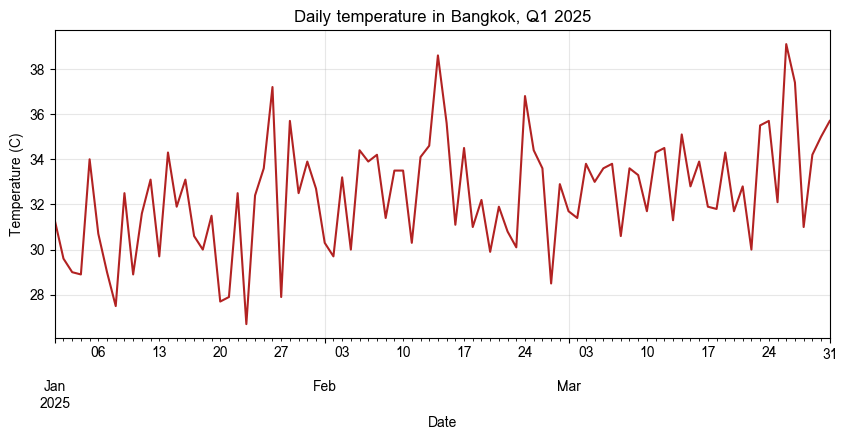

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# แนวปฏิบัติที่แนะนำคือสร้าง figure และ axes ขึ้นก่อน แล้วส่ง ax เข้าไปในคำสั่ง plot
bangkok = df[df["city"] == "Bangkok"].sort_values("date")

fig, ax = plt.subplots(figsize=(10, 4))
bangkok.plot(x="date", y="temperature_c", ax=ax, color="firebrick", legend=False)
ax.set_title("Daily temperature in Bangkok, Q1 2025")
ax.set_xlabel("Date")
ax.set_ylabel("Temperature (C)")
ax.grid(alpha=0.3)
plt.show()

### ตัวอย่างที่ 2 กราฟแท่งแนวตั้งและแนวนอน

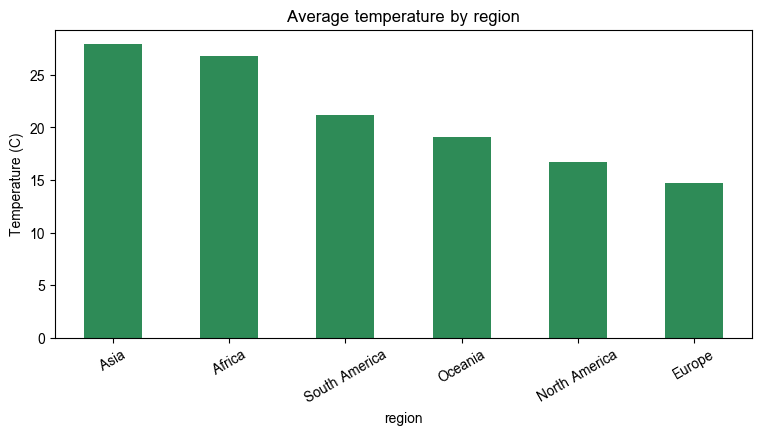

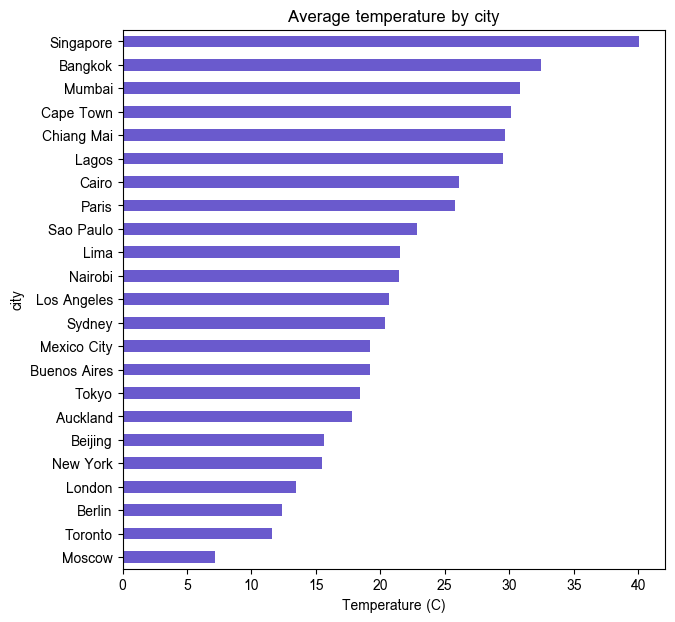

In [ ]:
avg_by_region = df.groupby("region")["temperature_c"].mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 4))
avg_by_region.plot(kind="bar", ax=ax, color="seagreen")
ax.set_title("Average temperature by region")
ax.set_ylabel("Temperature (C)")
ax.tick_params(axis="x", rotation=30)
plt.show()

avg_by_city = df.groupby("city")["temperature_c"].mean().sort_values()
fig, ax = plt.subplots(figsize=(7, 7))
avg_by_city.plot(kind="barh", ax=ax, color="slateblue")
ax.set_title("Average temperature by city")
ax.set_xlabel("Temperature (C)")
plt.show()

### ตัวอย่างที่ 3 ฮิสโตแกรม กราฟจุด และ boxplot

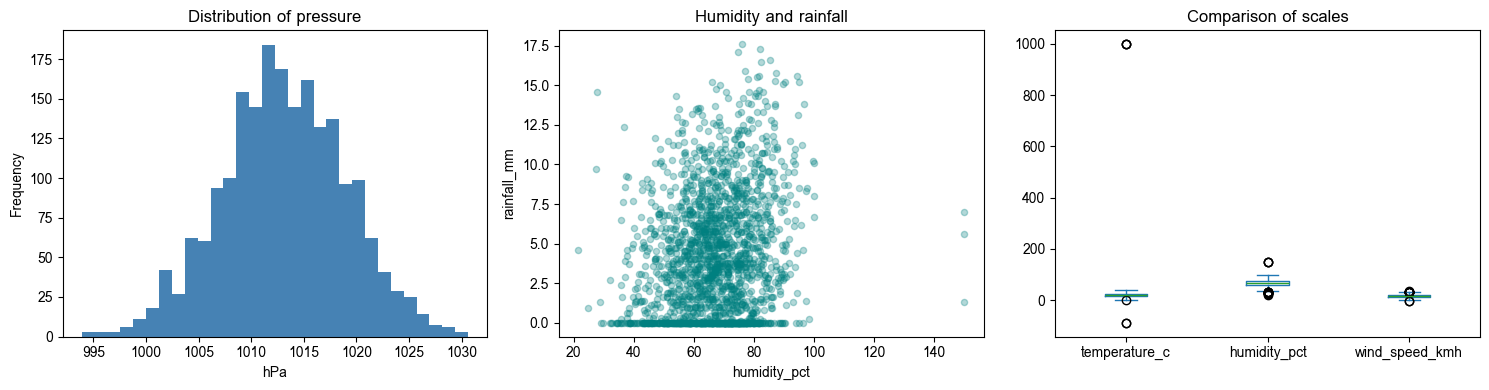

In [ ]:
# การวางกราฟหลายรูปในภาพเดียว ให้สร้าง axes เป็นกริดแล้วส่งแต่ละช่องเข้าไปด้วยพารามิเตอร์ ax
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

df["pressure_hpa"].plot(kind="hist", bins=30, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of pressure")
axes[0].set_xlabel("hPa")

df.plot(kind="scatter", x="humidity_pct", y="rainfall_mm", alpha=0.3, ax=axes[1], color="teal")
axes[1].set_title("Humidity and rainfall")

df[["temperature_c", "humidity_pct", "wind_speed_kmh"]].plot(kind="box", ax=axes[2])
axes[2].set_title("Comparison of scales")

plt.tight_layout()
plt.show()

### ตัวอย่างที่ 4 กราฟวงกลมและการนับสัดส่วน

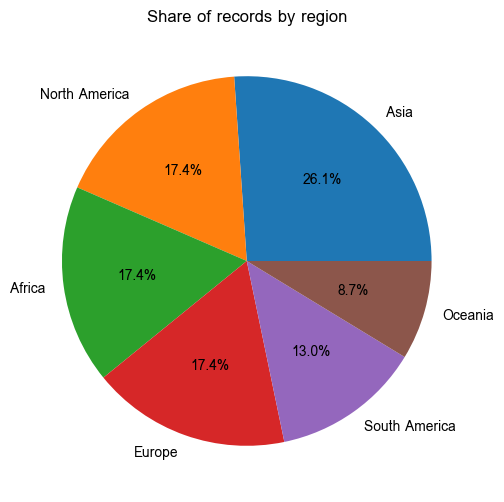

In [ ]:
fig, ax = plt.subplots(figsize=(6, 6))
df["region"].value_counts().plot(kind="pie", ax=ax, autopct="%1.1f%%", ylabel="")
ax.set_title("Share of records by region")
plt.show()

### ตัวอย่างที่ 5 การวาดหลายคอลัมน์พร้อมกัน ด้วย `subplots` และ `secondary_y`

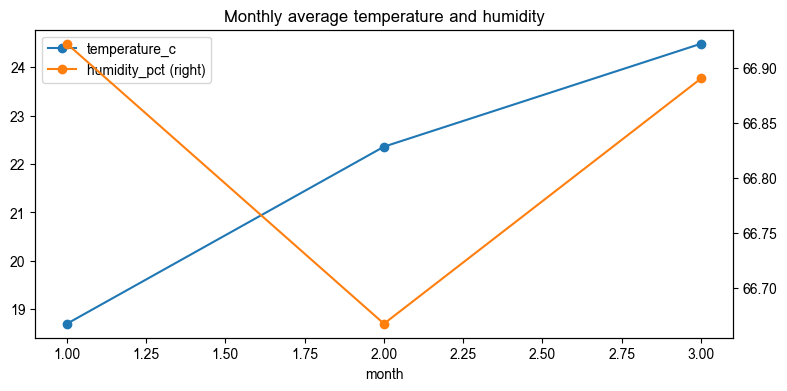

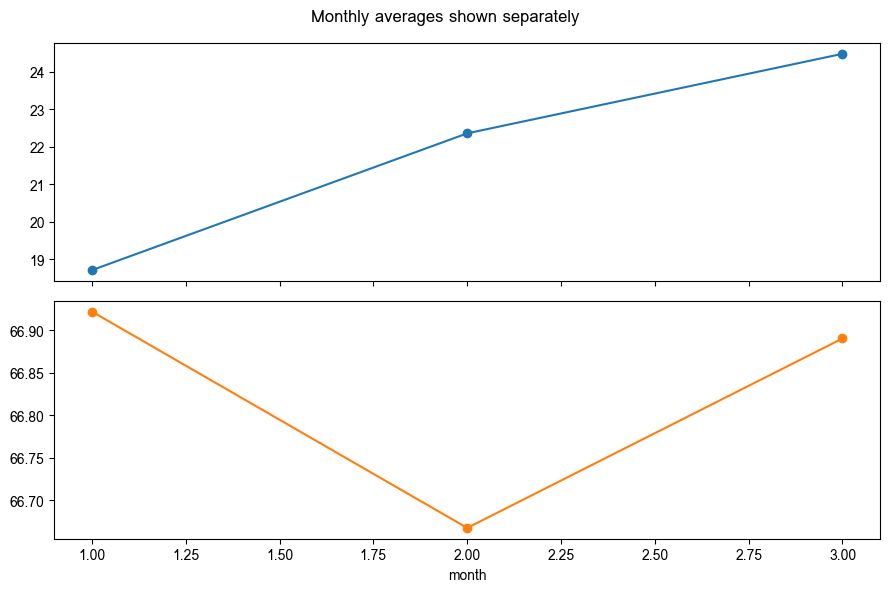

In [ ]:
monthly = df.groupby("month")[["temperature_c", "humidity_pct"]].mean()

# secondary_y ใช้แกน y ด้านขวาสำหรับคอลัมน์ที่มีสเกลต่างกันมาก
fig, ax = plt.subplots(figsize=(9, 4))
monthly.plot(ax=ax, marker="o", secondary_y="humidity_pct")
ax.set_title("Monthly average temperature and humidity")
plt.show()

# subplots=True แยกแต่ละคอลัมน์ออกเป็นกราฟย่อย
axes = monthly.plot(subplots=True, layout=(2, 1), figsize=(9, 6), marker="o", legend=False)
plt.suptitle("Monthly averages shown separately")
plt.tight_layout()
plt.show()

### ตัวอย่างที่ 6 กราฟแท่งซ้อนจากตารางไขว้

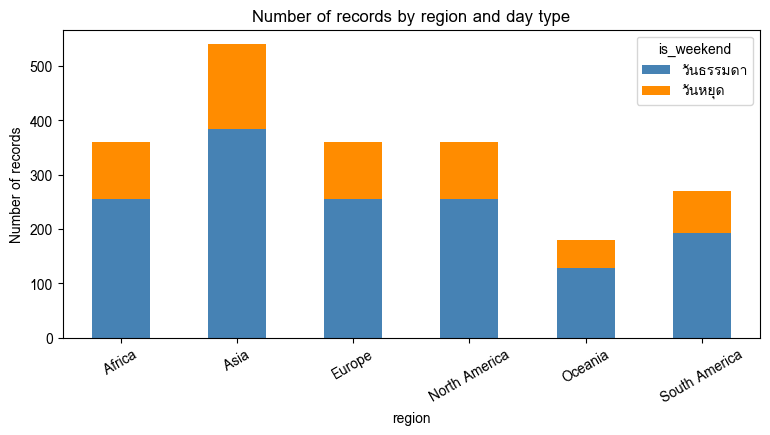

In [ ]:
df["is_weekend"] = df["date"].dt.dayofweek >= 5
weekend_by_region = (df.groupby(["region", "is_weekend"]).size()
                       .unstack(fill_value=0)
                       .rename(columns={False: "วันธรรมดา", True: "วันหยุด"}))

fig, ax = plt.subplots(figsize=(9, 4))
weekend_by_region.plot(kind="bar", stacked=True, ax=ax, color=["steelblue", "darkorange"])
ax.set_title("Number of records by region and day type")
ax.set_ylabel("Number of records")
ax.tick_params(axis="x", rotation=30)
plt.show()

### ตัวอย่างที่ 7 กราฟเชิงสถิติด้วย seaborn

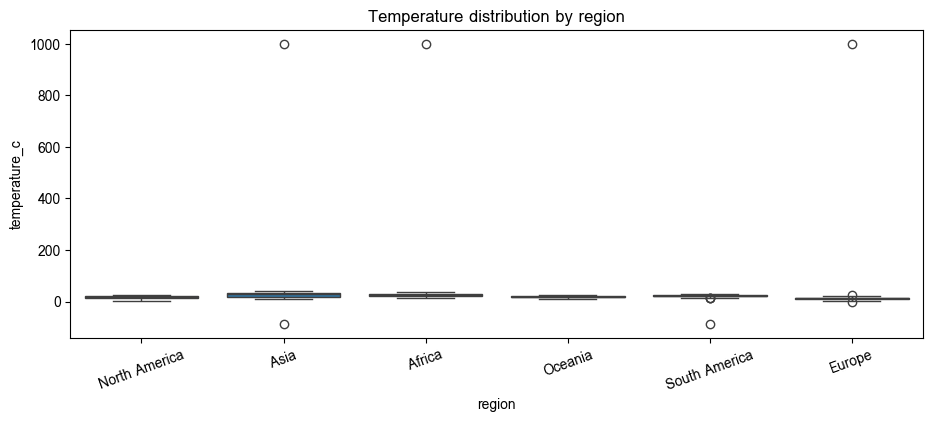

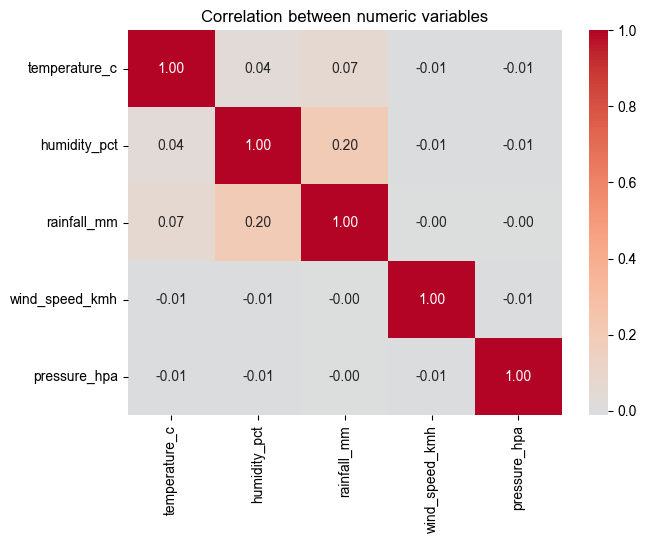

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4))
sns.boxplot(data=df, x="region", y="temperature_c", ax=ax)
ax.set_title("Temperature distribution by region")
ax.tick_params(axis="x", rotation=20)
plt.show()

numeric_cols = ["temperature_c", "humidity_pct", "rainfall_mm", "wind_speed_kmh", "pressure_hpa"]
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation between numeric variables")
plt.show()

### โจทย์ 17.1
สร้างกราฟสี่รูปจาก DataFrame โดยใช้ `.plot()` พร้อมกำหนดชื่อกราฟและชื่อแกนให้ครบทุกรูป

1. กราฟเส้นแสดงแนวโน้มอุณหภูมิรายวันของสามเมืองในรูปเดียวกัน พร้อมคำอธิบายสัญลักษณ์
2. กราฟแท่งแนวนอนแสดงปริมาณฝนรวมรายเมือง เรียงจากมากไปน้อย
3. ฮิสโตแกรมของ `wind_speed_kmh` โดยทดลองกำหนด `bins` สามค่าที่ต่างกันและอธิบายผลของการเลือก `bins`
4. กราฟจุดระหว่าง `population_millions` กับอุณหภูมิเฉลี่ยรายเมือง

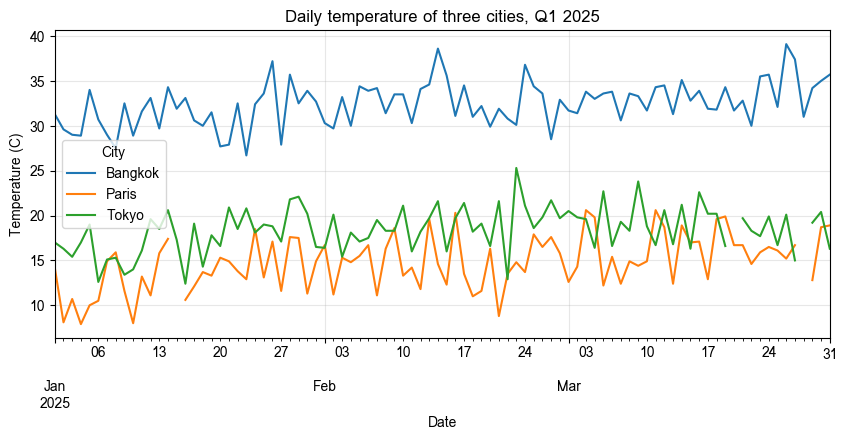

In [ ]:
# คำตอบข้อ 17.1
def plot_temp_lines(ax, cities=("Bangkok", "Tokyo", "Paris")):
    daily = (
        df[df["city"].isin(cities)]
          .assign(temp_ok=lambda d: d["temperature_c"].where(d["temperature_c"].between(-60, 60)))   # ตัดค่าผิดปกติ
          .pivot_table(index="date", columns="city", values="temp_ok")       # แต่ละเมืองเป็นหนึ่งคอลัมน์ = หนึ่งเส้น
    )
    daily.plot(ax=ax, linewidth=1.5)
    ax.set_title("Daily temperature of three cities, Q1 2025")
    ax.set_xlabel("Date")
    ax.set_ylabel("Temperature (C)")
    ax.legend(title="City")
    ax.grid(alpha=0.3)

fig, ax = plt.subplots(figsize=(10, 4))
plot_temp_lines(ax)
plt.show()

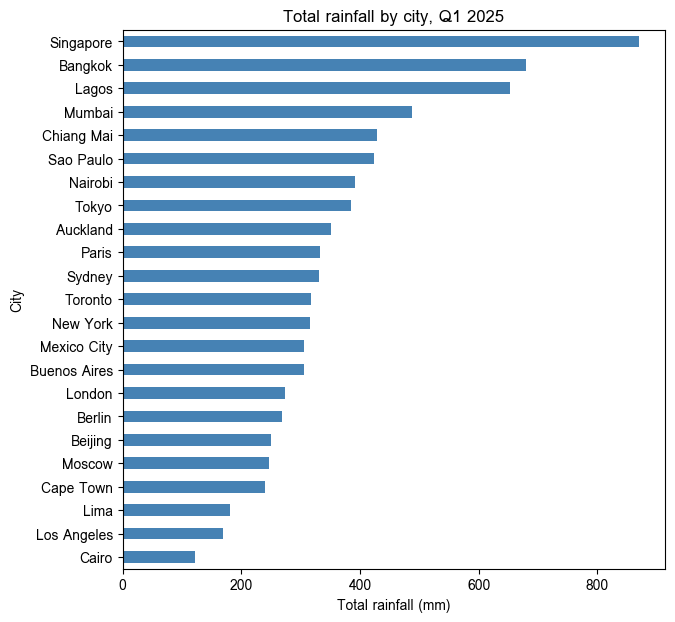

In [ ]:
def plot_rain_bars(ax):
    # barh วาดจากล่างขึ้นบน จึงเรียงจากน้อยไปมาก เพื่อให้เมืองที่ฝนมากที่สุดอยู่บนสุด
    total_rain = df.groupby("city")["rainfall_mm"].sum().sort_values()
    total_rain.plot(kind="barh", ax=ax, color="steelblue")
    ax.set_title("Total rainfall by city, Q1 2025")
    ax.set_xlabel("Total rainfall (mm)")
    ax.set_ylabel("City")

fig, ax = plt.subplots(figsize=(7, 7))
plot_rain_bars(ax)
plt.show()

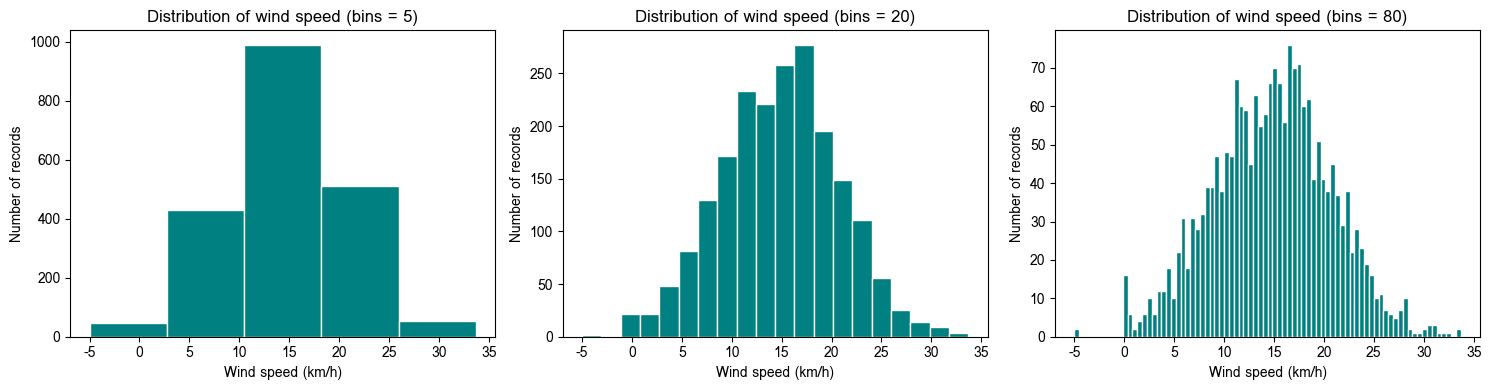

In [ ]:
def plot_wind_hist(ax, bins=20):
    df["wind_speed_kmh"].plot(kind="hist", bins=bins, ax=ax, color="teal", edgecolor="white")
    ax.set_title(f"Distribution of wind speed (bins = {bins})")
    ax.set_xlabel("Wind speed (km/h)")
    ax.set_ylabel("Number of records")

bins_to_try = [5, 20, 80]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
plot_wind_hist(axes[0], bins=bins_to_try[0])
plot_wind_hist(axes[1], bins=bins_to_try[1])
plot_wind_hist(axes[2], bins=bins_to_try[2])
plt.tight_layout()
plt.show()

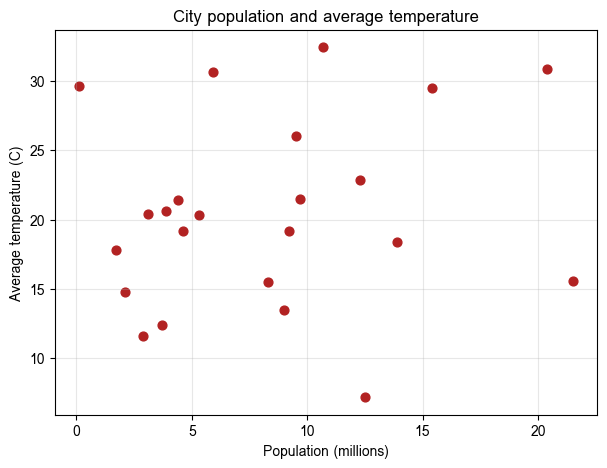

In [ ]:
city_points = (
    df.assign(temp_ok=lambda d: d["temperature_c"].where(d["temperature_c"].between(-60, 60)))
      .groupby("city", as_index=False)
      .agg(avg_temp=("temp_ok", "mean"))
      .merge(city_info[["city", "population_millions"]], on="city", how="left", validate="one_to_one")
)

def plot_pop_scatter(ax):
    city_points.plot(kind="scatter", x="population_millions", y="avg_temp", ax=ax, color="firebrick", s=40)
    ax.set_title("City population and average temperature")
    ax.set_xlabel("Population (millions)")
    ax.set_ylabel("Average temperature (C)")
    ax.grid(alpha=0.3)

fig, ax = plt.subplots(figsize=(7, 5))
plot_pop_scatter(ax)
plt.show()

### โจทย์ 17.2
นำผลลัพธ์ของโจทย์ 17.1 มาจัดวางในภาพเดียวกันด้วย `plt.subplots(2, 2)` พร้อมกำหนดชื่อรวมของภาพด้วย `plt.suptitle()`

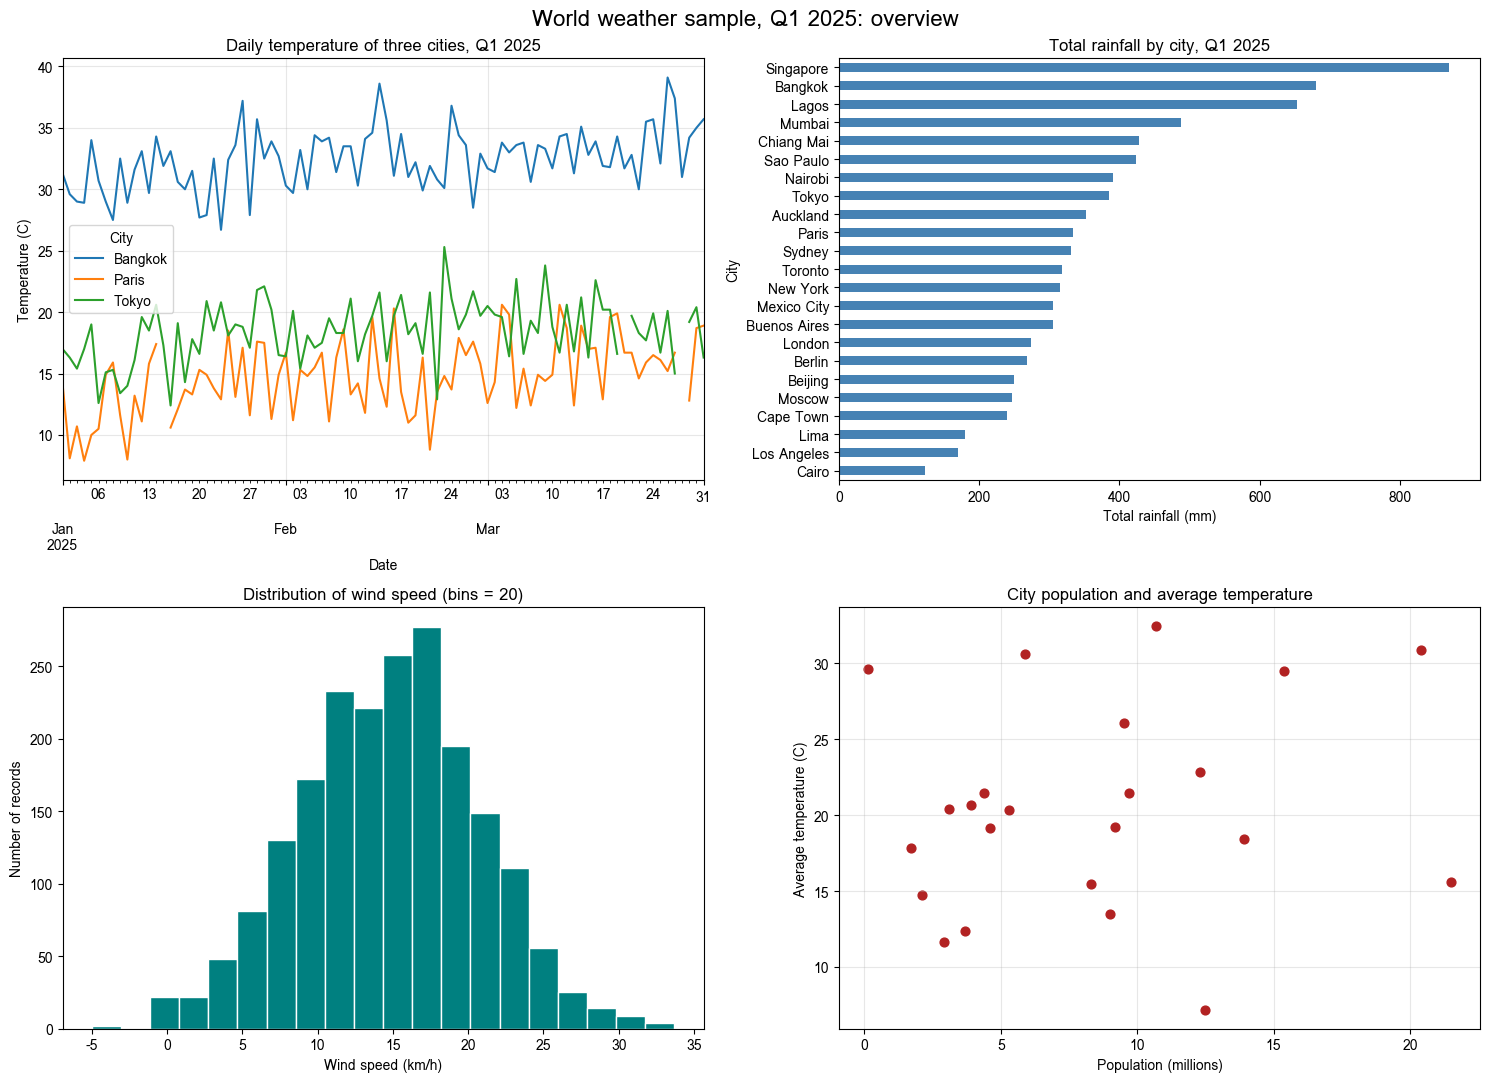

In [ ]:
# คำตอบข้อ 17.2
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

plot_temp_lines(axes[0, 0])
plot_rain_bars(axes[0, 1])
plot_wind_hist(axes[1, 0], bins=20)
plot_pop_scatter(axes[1, 1])

plt.suptitle("World weather sample, Q1 2025: overview", fontsize=16)
plt.tight_layout()
plt.show()

### โจทย์ 17.3
สร้างกราฟแท่งซ้อนแสดงจำนวนวันในแต่ละช่วงปริมาณฝน โดยแบ่งช่วงด้วย `pd.cut()` และจำแนกตามภูมิภาค
จากนั้นสร้างกราฟแบบ `stacked=False` เปรียบเทียบ
**อธิบาย:** กราฟแท่งซ้อนเหมาะสมกว่าในกรณีใด และกราฟแท่งเรียงข้างกันเหมาะสมกว่าในกรณีใด

rainfall_mm    No rain (0)  Light (0-5]  Moderate (5-10]  Heavy (>10)
region                                                               
Africa                 101          129               88           31
Asia                    59          174              203           90
Europe                 106          156               73           15
North America           92          161               84           11
Oceania                 35           68               60            9
South America           76          114               52           21


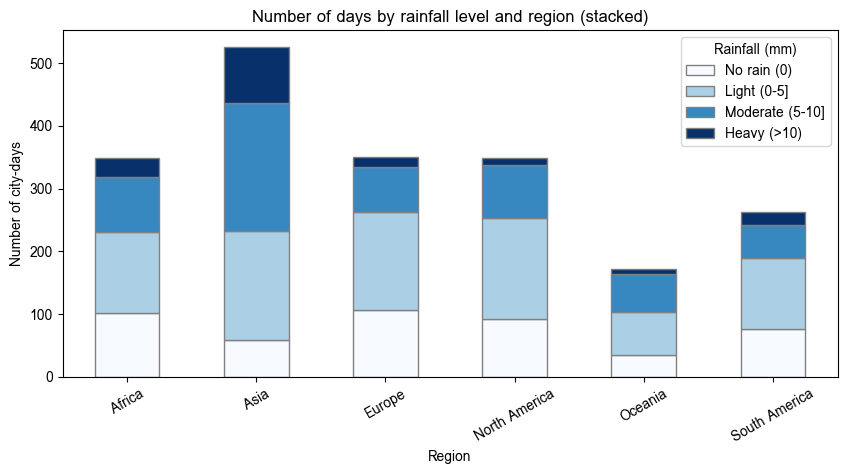

In [ ]:
# คำตอบข้อ 17.3
rain_level = pd.cut(
    df["rainfall_mm"],
    bins=[-0.001, 0, 5, 10, np.inf],
    labels=["No rain (0)", "Light (0-5]", "Moderate (5-10]", "Heavy (>10)"],
)
rain_by_region = pd.crosstab(df["region"], rain_level)
print(rain_by_region)

fig, ax = plt.subplots(figsize=(10, 4.5))
rain_by_region.plot(kind="bar", stacked=True, ax=ax, colormap="Blues", edgecolor="gray")
ax.set_title("Number of days by rainfall level and region (stacked)")
ax.set_xlabel("Region")
ax.set_ylabel("Number of city-days")
ax.legend(title="Rainfall (mm)")
ax.tick_params(axis="x", rotation=30)
plt.show()

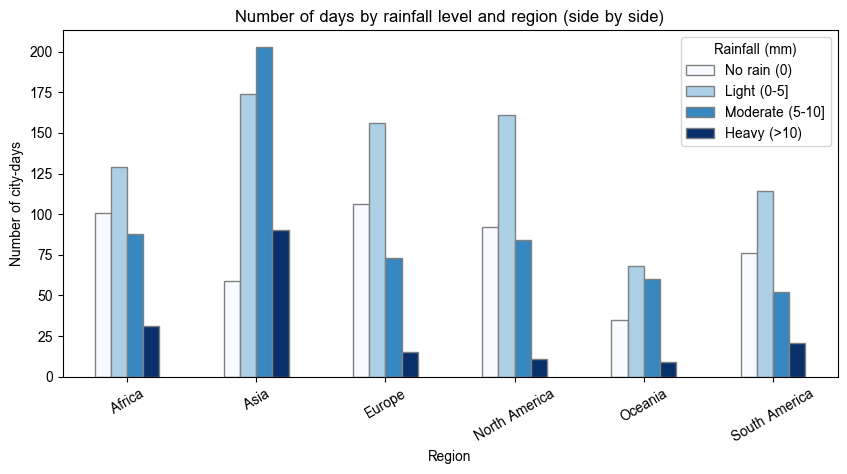

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
rain_by_region.plot(kind="bar", stacked=False, ax=ax, colormap="Blues", edgecolor="gray")
ax.set_title("Number of days by rainfall level and region (side by side)")
ax.set_xlabel("Region")
ax.set_ylabel("Number of city-days")
ax.legend(title="Rainfall (mm)")
ax.tick_params(axis="x", rotation=30)
plt.show()

### โจทย์ 17.4
สร้างกราฟด้วย seaborn สองรูป ได้แก่ boxplot ของ `rainfall_mm` จำแนกตามภูมิภาคและแยกสีตาม `is_weekend`
และ heatmap ของสหสัมพันธ์ระหว่าง `temperature_c`, `humidity_pct`, `rainfall_mm` และ `population_millions`
พร้อมตีความผลที่ได้เป็นข้อความ

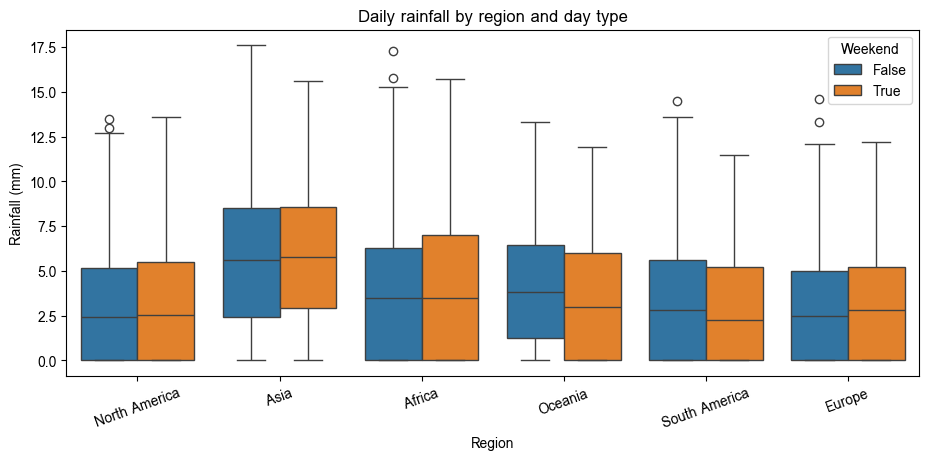

In [ ]:
# คำตอบข้อ 17.4
box_data = df.assign(is_weekend=lambda d: d["date"].dt.dayofweek >= 5)

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.boxplot(data=box_data, x="region", y="rainfall_mm", hue="is_weekend", ax=ax)
ax.set_title("Daily rainfall by region and day type")
ax.set_xlabel("Region")
ax.set_ylabel("Rainfall (mm)")
ax.legend(title="Weekend")
ax.tick_params(axis="x", rotation=20)
plt.show()

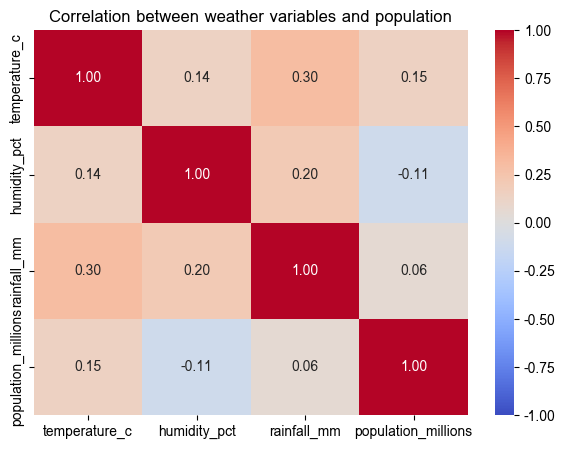

In [ ]:
corr_cols = ["temperature_c", "humidity_pct", "rainfall_mm", "population_millions"]
corr_matrix = (
    df.merge(city_info[["city", "population_millions"]], on="city", how="left", validate="many_to_one")
      .assign(temperature_c=lambda d: d["temperature_c"].where(d["temperature_c"].between(-60, 60)),
              humidity_pct=lambda d: d["humidity_pct"].where(d["humidity_pct"].between(0, 100)))
      [corr_cols]
      .corr()
)

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation between weather variables and population")
plt.show()


---
## ข้อ 18 โจทย์ประยุกต์รวม

ให้ใช้ตารางที่รวมข้อมูลจากทั้ง 3 แหล่งและผ่านการทำความสะอาดแล้ว ตอบคำถามต่อไปนี้
แต่ละข้อต้องประกอบด้วย **ตารางหรือกราฟหนึ่งชิ้น** และ **ข้อสรุปเป็นข้อความสั้น ๆ**

**ข้อกำหนดเพิ่มเติม**

- ให้เขียนโปรแกรมในรูปแบบลำดับต่อเนื่องที่อ่านเข้าใจได้ ไม่ใช้ตัวแปรชั่วคราวจำนวนมากโดยไม่จำเป็น
- ห้ามใช้การวนซ้ำทีละแถว
- หากข้อสรุปขึ้นอยู่กับวิธีจัดการค่าว่างหรือค่าผิดปกติ ให้ระบุวิธีที่เลือกใช้ไว้ด้วย

1. ภูมิภาคใดมีสภาพอากาศแปรปรวนมากที่สุดในไตรมาสแรก เมื่อวัดจากส่วนเบี่ยงเบนมาตรฐานของอุณหภูมิรายวัน
   และความแปรปรวนดังกล่าวเกิดจากทุกเมืองในภูมิภาคนั้นเท่ากันหรือเกิดจากเมืองใดเมืองหนึ่งเป็นหลัก

In [ ]:
# คำตอบข้อ 18.1
base_cols = ["record_id", "date", "month", "city", "country", "region",
             "temperature_c", "humidity_pct", "rainfall_mm", "wind_speed_kmh", "pressure_hpa"]

clean = (
    df[base_cols]
      .assign(
          temperature_c=lambda d: d["temperature_c"].where(d["temperature_c"].between(-60, 60)),
          humidity_pct=lambda d: d["humidity_pct"].where(d["humidity_pct"].between(0, 100)),
          wind_speed_kmh=lambda d: d["wind_speed_kmh"].where(d["wind_speed_kmh"] >= 0),
      )
      .pipe(add_lookup, city_info, "city")
      .pipe(add_lookup, region_info, "region")
)

print("รูปร่าง:", clean.shape, "| คีย์ (city, date) ซ้ำ:", clean.duplicated(subset=["city", "date"]).sum())
print("จำนวนค่าว่างของตัวแปรหลัก")
print(clean[["temperature_c", "humidity_pct", "rainfall_mm", "wind_speed_kmh", "population_millions"]].isna().sum().to_string())
clean.head(3)

รูปร่าง: (2070, 15) | คีย์ (city, date) ซ้ำ: 0
จำนวนค่าว่างของตัวแปรหลัก
temperature_c          25
humidity_pct           85
rainfall_mm            62
wind_speed_kmh         43
population_millions     0


,record_id,date,month,city,country,region,temperature_c,humidity_pct,rainfall_mm,wind_speed_kmh,pressure_hpa,population_millions,timezone,continent_code,avg_gdp_growth_pct
0,983,2025-03-24,3,New York,USA,North America,15.7,72.6,6.3,15.9,1005.4,8.3,UTC-5,NAM,2.3
1,220,2025-02-09,2,Tokyo,Japan,Asia,18.3,60.6,0.0,20.5,1015.1,13.9,UTC+9,AS,4.2
2,1022,2025-02-01,2,Los Angeles,USA,North America,20.6,46.8,1.2,8.6,1013.5,3.9,UTC-8,NAM,2.3


In [ ]:
city_temp = clean.groupby(["region", "city"])["temperature_c"].agg(["mean", "std"])

region_variability = (
    clean.groupby("region")
         .agg(std_all_days=("temperature_c", "std"), n_valid=("temperature_c", "count"))
         .assign(
             mean_std_within_city=city_temp.groupby(level="region")["std"].mean(),
             std_between_city_means=city_temp.groupby(level="region")["mean"].std(),
             n_cities=city_temp.groupby(level="region").size(),
         )
         .sort_values("std_all_days", ascending=False)
         .round(2)
)
top_region = region_variability.index[0]
region_variability

,std_all_days,n_valid,mean_std_within_city,std_between_city_means,n_cities
region,,,,,
Asia,7.16,535,2.67,7.28,6
Africa,4.88,352,2.79,4.64,4
North America,4.52,357,2.87,4.05,4
Europe,4.07,354,2.88,3.32,4
Oceania,3.08,180,2.81,1.80,2
South America,3.06,267,2.89,1.23,3


In [ ]:
top_region_cities = (
    clean[clean["region"] == top_region]
      .assign(sq_dev=lambda d: (d["temperature_c"] - d["temperature_c"].mean()) ** 2)
      .groupby("city")
      .agg(avg_temp=("temperature_c", "mean"), std_temp=("temperature_c", "std"), sum_sq=("sq_dev", "sum"))
      .assign(share_of_variance_pct=lambda d: d["sum_sq"] / d["sum_sq"].sum() * 100)
      .drop(columns="sum_sq")
      .sort_values("share_of_variance_pct", ascending=False)
      .round(2)
)

equal_share = 100 / len(top_region_cities)
row = region_variability.loc[top_region]
print(f"สรุป: ภูมิภาคที่อุณหภูมิรายวันแปรปรวนมากที่สุดคือ {top_region} (std = {row['std_all_days']} องศา)")
print(f"  - std ภายในเมืองโดยเฉลี่ย = {row['mean_std_within_city']} องศา "
      f"| std ของค่าเฉลี่ยรายเมือง = {row['std_between_city_means']} องศา")
print(f"  - ถ้าทุกเมืองมีส่วนเท่ากัน แต่ละเมืองจะมีส่วน {equal_share:.1f} % "
      f"| เมืองที่มีส่วนมากที่สุดคือ {top_region_cities.index[0]} "
      f"({top_region_cities['share_of_variance_pct'].iloc[0]} %)")
top_region_cities

สรุป: ภูมิภาคที่อุณหภูมิรายวันแปรปรวนมากที่สุดคือ Asia (std = 7.16 องศา)
  - std ภายในเมืองโดยเฉลี่ย = 2.67 องศา | std ของค่าเฉลี่ยรายเมือง = 7.28 องศา
  - ถ้าทุกเมืองมีส่วนเท่ากัน แต่ละเมืองจะมีส่วน 16.7 % | เมืองที่มีส่วนมากที่สุดคือ Beijing (39.9 %)


,avg_temp,std_temp,share_of_variance_pct
city,,,
Beijing,15.60,2.87,39.90
Tokyo,18.41,2.52,22.01
Bangkok,32.44,2.49,14.39
Mumbai,30.87,2.54,8.97
Singapore,30.64,2.71,8.38
Chiang Mai,29.65,2.86,6.34


2. เมืองที่มีฝนตกหนักบ่อยที่สุด 5 อันดับแรกเมื่อวัดด้วยสัดส่วน ให้เปรียบเทียบกับผลที่ได้เมื่อวัดด้วยจำนวนวัน
   และอธิบายว่าเหตุใดจึงให้ผลต่างกัน

In [ ]:
# คำตอบข้อ 18.2
heavy_rank = (
    clean.groupby("city")
         .agg(heavy_days=("rainfall_mm", lambda s: (s > 10).sum()),
              n_valid_days=("rainfall_mm", "count"))                # จำนวนวันที่มีข้อมูลฝน (ตัวหาร)
         .assign(
             heavy_pct=lambda d: d["heavy_days"] / d["n_valid_days"] * 100,
             rank_by_pct=lambda d: d["heavy_pct"].rank(method="min", ascending=False).astype(int),
             rank_by_days=lambda d: d["heavy_days"].rank(method="min", ascending=False).astype(int),
         )
         .sort_values(["heavy_pct", "heavy_days"], ascending=False)
         .round({"heavy_pct": 2})
)

top5_pct = heavy_rank.nlargest(5, "heavy_pct").index.tolist()
top5_days = heavy_rank.nlargest(5, "heavy_days").index.tolist()

print("สรุป: 5 อันดับตามสัดส่วน :", top5_pct)
print("      5 อันดับตามจำนวนวัน:", top5_days)
print("      เป็นเมืองชุดเดียวกัน:", set(top5_pct) == set(top5_days),
      "| ลำดับเหมือนกันทุกอันดับ:", top5_pct == top5_days)
print("      จำนวนวันที่มีข้อมูลฝนรายเมือง (ตัวหาร): ต่ำสุด", heavy_rank["n_valid_days"].min(),
      "สูงสุด", heavy_rank["n_valid_days"].max())
heavy_rank.head(8)

สรุป: 5 อันดับตามสัดส่วน : ['Singapore', 'Bangkok', 'Lagos', 'Sao Paulo', 'Chiang Mai']
      5 อันดับตามจำนวนวัน: ['Singapore', 'Bangkok', 'Lagos', 'Sao Paulo', 'Chiang Mai']
      เป็นเมืองชุดเดียวกัน: True | ลำดับเหมือนกันทุกอันดับ: True
      จำนวนวันที่มีข้อมูลฝนรายเมือง (ตัวหาร): ต่ำสุด 85 สูงสุด 90


,heavy_days,n_valid_days,heavy_pct,rank_by_pct,rank_by_days
city,,,,,
Singapore,44,90,48.89,1,1
Bangkok,23,87,26.44,2,2
Lagos,22,88,25.00,3,3
Sao Paulo,11,88,12.50,4,4
Chiang Mai,9,85,10.59,5,5
Buenos Aires,9,88,10.23,6,5
Nairobi,8,87,9.20,7,7
Mumbai,7,88,7.95,8,8


3. จำนวนประชากรของเมืองมีความสัมพันธ์กับอุณหภูมิหรือปริมาณฝนหรือไม่
   ให้คำนวณค่าสหสัมพันธ์ประกอบ พร้อมระบุข้อควรระวังในการตีความอย่างน้อยหนึ่งประการ

In [ ]:
# คำตอบข้อ 18.3
city_level = clean.groupby("city").agg(
    population_millions=("population_millions", "first"),
    avg_temp=("temperature_c", "mean"),
    avg_daily_rain=("rainfall_mm", "mean"),
)

pop_corr = pd.DataFrame({
    "pearson": city_level.corr(method="pearson")["population_millions"],
    "spearman": city_level.corr(method="spearman")["population_millions"],      # ทนต่อเมืองที่ประชากรสูงผิดจากกลุ่ม
}).drop(index="population_millions").round(3)

print("สรุป: จำนวนเมืองที่ใช้คำนวณ =", len(city_level))
print(f"      ประชากรกับอุณหภูมิเฉลี่ย : pearson r = {pop_corr.loc['avg_temp', 'pearson']}, "
      f"spearman = {pop_corr.loc['avg_temp', 'spearman']}")
print(f"      ประชากรกับฝนเฉลี่ยต่อวัน : pearson r = {pop_corr.loc['avg_daily_rain', 'pearson']}, "
      f"spearman = {pop_corr.loc['avg_daily_rain', 'spearman']}")
pop_corr

สรุป: จำนวนเมืองที่ใช้คำนวณ = 23
      ประชากรกับอุณหภูมิเฉลี่ย : pearson r = 0.159, spearman = 0.23
      ประชากรกับฝนเฉลี่ยต่อวัน : pearson r = 0.123, spearman = 0.057


,pearson,spearman
avg_temp,0.159,0.230
avg_daily_rain,0.123,0.057


4. เดือนใดของแต่ละภูมิภาคที่ควรหลีกเลี่ยงการเดินทางมากที่สุด
   ให้กำหนดเกณฑ์การตัดสินใจจากข้อมูลที่มีอยู่ และอธิบายเหตุผลของการเลือกเกณฑ์ดังกล่าว

In [ ]:
# คำตอบข้อ 18.4
travel = (
    clean.assign(
        heavy_rain=lambda d: d["rainfall_mm"] > 10,
        strong_wind=lambda d: d["wind_speed_kmh"] > 25,
        extreme_temp=lambda d: (d["temperature_c"] > 35) | (d["temperature_c"] < 5),
        bad_day=lambda d: d["heavy_rain"] | d["strong_wind"] | d["extreme_temp"],
    )
    .groupby(["region", "month"])[["bad_day", "heavy_rain", "strong_wind", "extreme_temp"]]
    .mean()
    .mul(100)
    .round(1)
)

bad_day_pct = travel["bad_day"].unstack("month")
month_to_avoid = bad_day_pct.assign(
    month_to_avoid=bad_day_pct.idxmax(axis=1),
    pct_bad_days=bad_day_pct.max(axis=1),
    main_reason=travel.loc[
        list(zip(bad_day_pct.index, bad_day_pct.idxmax(axis=1))), ["heavy_rain", "strong_wind", "extreme_temp"]
    ].idxmax(axis=1).to_numpy(),
)

conclusion = (
    month_to_avoid.index.to_series() + " : ควรหลีกเลี่ยงเดือน " + month_to_avoid["month_to_avoid"].astype(str)
    + " (วันที่ไม่เหมาะกับการเดินทาง " + month_to_avoid["pct_bad_days"].astype(str) + " %"
    + " สาเหตุหลัก " + month_to_avoid["main_reason"] + ")"
)
print("สรุป")
print("\n".join(conclusion))
month_to_avoid

สรุป
Africa : ควรหลีกเลี่ยงเดือน 1 (วันที่ไม่เหมาะกับการเดินทาง 12.9 % สาเหตุหลัก heavy_rain)
Asia : ควรหลีกเลี่ยงเดือน 2 (วันที่ไม่เหมาะกับการเดินทาง 25.0 % สาเหตุหลัก heavy_rain)
Europe : ควรหลีกเลี่ยงเดือน 2 (วันที่ไม่เหมาะกับการเดินทาง 13.4 % สาเหตุหลัก extreme_temp)
North America : ควรหลีกเลี่ยงเดือน 1 (วันที่ไม่เหมาะกับการเดินทาง 7.3 % สาเหตุหลัก heavy_rain)
Oceania : ควรหลีกเลี่ยงเดือน 3 (วันที่ไม่เหมาะกับการเดินทาง 9.7 % สาเหตุหลัก heavy_rain)
South America : ควรหลีกเลี่ยงเดือน 1 (วันที่ไม่เหมาะกับการเดินทาง 11.8 % สาเหตุหลัก heavy_rain)


month,1,2,3,month_to_avoid,pct_bad_days,main_reason
region,,,,,,
Africa,12.9,9.8,10.5,1,12.9,heavy_rain
Asia,20.4,25.0,22.0,2,25.0,heavy_rain
Europe,12.9,13.4,11.3,2,13.4,extreme_temp
North America,7.3,6.2,7.3,1,7.3,heavy_rain
Oceania,6.5,5.4,9.7,3,9.7,heavy_rain
South America,11.8,9.5,11.8,1,11.8,heavy_rain


---

<center>จบแล้ว ขอแสดงความยินดีกับทุกคน

<center>> เขียนเองหนึ่งบรรทัด ได้ความเข้าใจมากกว่าอ่านผ่านตาสิบบรรทัด
> One line you write yourself teaches more than ten you only read.

> คนที่จัดการข้อมูลสองพันแถวได้อย่างสะอาดหมดจด คือคนเดียวกับที่จะจัดการข้อมูลสองล้านแถวได้อย่างมั่นใจ
> Whoever handles two thousand rows with care will handle two million with confidence.

<center>❤️❤️❤️❤️❤️ Keep Learning ❤️❤️❤️❤️❤️